<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 1 DO PROJETO</b></CENTER><br/>

NOME COMPLETO: George Lucas

LINK PARA SEU PRÓPRIO COLAB: [Aqui](https://)

LINK PARA SEU PRÓPRIO GITHUB: [Aqui](https://)

LINK PARA SEU VÍDEO NO YOUTUBE: [Aqui](https://)

<center>

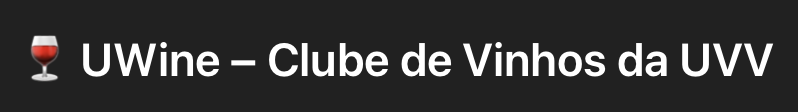

<center>

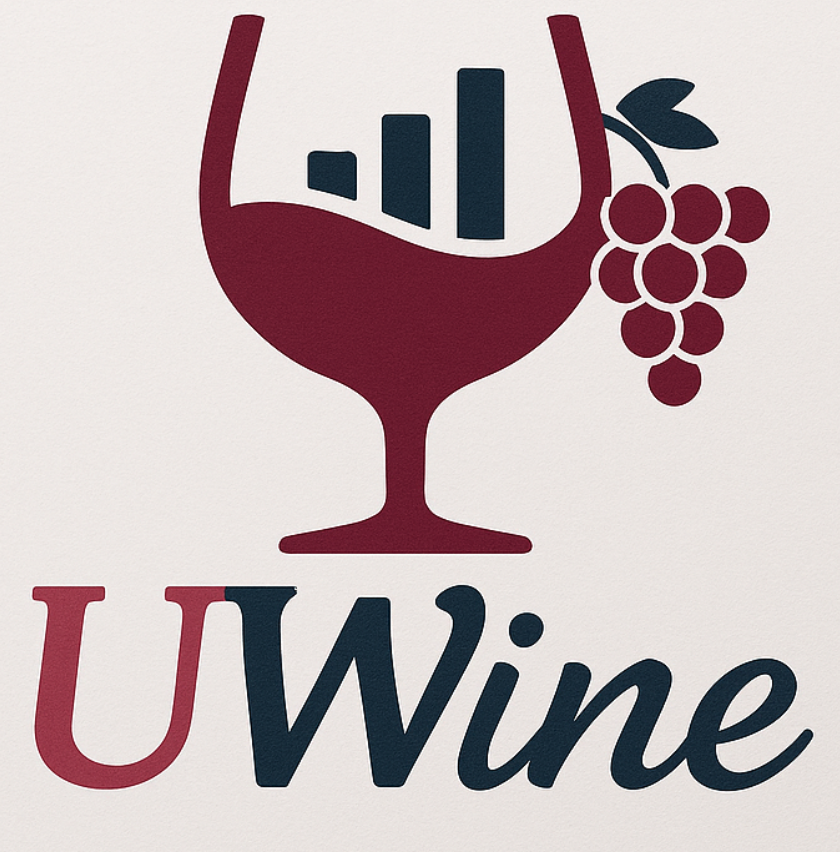

# **Cenário Fictício**:

Prezados(as) alunos(as),

É com entusiasmo que apresento a proposta do **Projeto de Conclusão de Curso (TCC)** para os estudantes do curso de Ciência de Dados da Universidade Vila Velha: o UWine – Clube de Vinhos da UVV.

A proposta do projeto consiste na análise de um Clube de Vinhos universitário fictício, com base em dados simulados, que será totalmente orientado por técnicas e práticas de Ciência de Dados.

Sendo assim, você foi designado como **Consultor em Ciência de Dados** ( ***Data Science Consultant*** ) para fazer uma análise completa dos dados dos clientes a partir de um conjunto de dados (Amostra) com mais de 1 milhão de notas fiscais (~ 350 Megabytes). Além disso, há uma entrada diária de aproximadamente umas 5000 novas notas fiscais no sistema.

O objetivo é permitir que cada consultor(a) percorra foco analíticos diferentes dentro do mesmo ecossistema de dados, aplicando modelos de machine learning supervisionado ou não supervisionado, análise preditiva, dashboards interativos, entre outros.

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do ***Projeto UWine***, adotaremos um workflow composto por cinco etapas principais, alinhadas às boas práticas da Ciência de Dados. Cada etapa representa um marco do processo analítico, permitindo que cada analista avance de forma estruturada do entendimento inicial dos dados até a entrega final dos insights.

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
from IPython.display import HTML, Markdown, display

SEED = 42  # semente única: todos os sorteios do notebook partem dela

pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 100)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110,
    'figure.constrained_layout.use': True,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7',
    'grid.color': '#e1e0d9',
    'grid.linewidth': 0.7,
    'legend.frameon': False,
})

# Nomes de colunas usados o tempo todo
TOTAL, RENDA, PLANO = 'TOTAL (R$)', 'RENDA BRUTO (R$)', 'TIPO DA CONTA'
OPINIAO, NOTA, NIVEL = 'OPINIÃO DO CLIENTE', 'NOTA DE SATISFAÇÃO (%)', 'NÍVEL DE SATISFAÇÃO'

# Cada plano tem sempre a mesma cor em todos os gráficos
PLANOS = ['ESSENTIAL', 'VIP', 'PRIME']
CORES_PLANO = {'ESSENTIAL': '#2a78d6', 'VIP': '#eb6834', 'PRIME': '#1baf7a'}

# Escala da pesquisa (a da figura do enunciado), do pior para o melhor
NIVEIS = ['Muito insatisfeito', 'Insatisfeito', 'Indiferente', 'Satisfeito', 'Muito satisfeito']
CORES_NIVEL = dict(zip(NIVEIS, ['#b3302f', '#ec8a86', '#a9a79f', '#86b6ef', '#256abf']))

CORES_AMOSTRA = {'SAMPLE 1': '#4a3aa7', 'SAMPLE 2': '#eda100'}
CINZA = '#52514e'


def num(valor, casas=0):
    """Formata um número no padrão brasileiro: num(-1234.5, 1) -> '−1.234,5'."""
    texto = f'{abs(valor):,.{casas}f}'.replace(',', '_').replace('.', ',').replace('_', '.')
    negativo = valor < 0 and texto.strip('0,.') != ''
    return ('−' if negativo else '') + texto


def brl(valor, casas=2):
    """Formata um valor em reais: -1234.5 -> '−R$ 1.234,50'."""
    texto = num(valor, casas)
    return '−R$ ' + texto[1:] if texto.startswith('−') else 'R$ ' + texto


def pct(fracao, casas=1):
    """Formata uma fração como porcentagem: 0.1234 -> '12,3%'."""
    return num(100 * fracao, casas) + '%'


def fmt_p(p):
    """Formata um p-valor; abaixo de 0,001 escreve '< 0,001'."""
    return '< 0,001' if p < 0.001 else num(p, 3)


def tabela(df, casas=2, indice=True, titulo=None):
    """Exibe uma tabela com números no padrão brasileiro.

    Usa `casas` para decimais e mostra `titulo` acima da tabela, se informado.
    Valores ausentes aparecem como 'n/a' (não se aplica).
    """
    def formatar(valor):
        if isinstance(valor, (bool, np.bool_)):
            return valor
        if isinstance(valor, (int, np.integer)):
            return num(valor)
        if isinstance(valor, (float, np.floating)):
            return 'n/a' if np.isnan(valor) else num(valor, casas)
        return valor

    if titulo:
        display(Markdown('**' + titulo.replace('$', r'\$') + '**'))
    display(HTML(df.map(formatar).to_html(index=indice, border=0)))
    display(Markdown('&nbsp;'))


def eixo_reais(ax, eixo='y', marcas_log=(1, 2, 5)):
    """Escreve os rótulos de um eixo em reais; em escala log, marca 1, 2 e 5 de cada potência de 10."""
    alvo = ax.yaxis if eixo == 'y' else ax.xaxis
    if (ax.get_yscale() if eixo == 'y' else ax.get_xscale()) == 'log':
        alvo.set_major_locator(mticker.LogLocator(base=10, subs=marcas_log))
        alvo.set_minor_formatter(mticker.NullFormatter())
    alvo.set_major_formatter(mticker.FuncFormatter(lambda v, _: brl(v, 0)))


def eixo_milhar(ax, eixo='x'):
    """Escreve os rótulos de um eixo com separador de milhar (5.000)."""
    formato = mticker.FuncFormatter(lambda v, _: num(v))
    (ax.xaxis if eixo == 'x' else ax.yaxis).set_major_formatter(formato)


def mostrar(fig):
    """Exibe a figura e usa vírgula decimal nos eixos com formato padrão.
    """
    fig.draw_without_rendering()  # lê as marcas já no layout final
    for ax in fig.axes:
        for alvo in (ax.xaxis, ax.yaxis):
            if type(alvo.get_major_formatter()) is mticker.ScalarFormatter:
                marcas = np.asarray(alvo.get_ticklocs())
                casas = next((c for c in range(6) if np.allclose(np.round(marcas, c), marcas)), 6)
                alvo.set_major_locator(mticker.FixedLocator(marcas))
                alvo.set_major_formatter(mticker.FuncFormatter(lambda v, _, c=casas: num(v, c)))
    plt.show()

In [2]:
# load do seu TABLE aqui: Numero 26
table26 = pd.read_csv('table26.csv', index_col=0, encoding='utf-8')

In [3]:
table26.head()

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,MEAN: ash,MEAN: alcalinity_of_ash,MEAN: magnesium,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
0,1745995,SUL,MASCULINO,CASADO,0,3217.23,"Experiência regular, não atendeu a política de cashback da UVVine",68.68,11.963383,0.943074,2.335676,19.131564,92.487129,2.154782,1.654788,0.210049,1.977202,11.112515,0.881144,3.405761,529.185612,ESSENTIAL,420.23
1,4939566,SUL,MASCULINO,DESQUITADO(A) / VIÚVO(A),3,7809.65,Gostei do atendimento prestado pela UVVine,68.68,12.467793,2.072771,2.290014,20.745362,103.695056,1.281156,1.959841,0.323431,1.248029,-0.730165,0.806183,2.287086,1093.074177,VIP,548.67
2,6750767,SUDESTE,MASCULINO,CASADO,1,5558.84,Gostei do atendimento prestado pela UVVine,68.68,13.403409,3.769525,1.814532,22.694273,98.276497,1.454611,0.064181,0.403577,1.776799,4.462440,0.812552,1.383718,502.254751,ESSENTIAL,391.11
3,1614373,SUDESTE,MASCULINO,CASADO,1,3268.84,Gostei do atendimento prestado pela UVVine,68.68,12.745667,2.425497,2.048089,16.624721,99.606341,2.408494,1.552257,0.393725,1.959095,4.992713,0.615475,2.009869,322.114491,ESSENTIAL,426.94
4,6337962,SUDESTE,MASCULINO,SOLTEIRO,0,3268.12,Entrega foi boa e rápida na UVVine,68.68,13.919630,2.535430,2.378023,22.426215,105.215511,2.363159,2.363441,0.383081,1.668505,5.799382,0.720667,1.601304,636.422175,ESSENTIAL,394.16


In [4]:
table26.shape

(1120000, 23)

## Escopo da análise

Cada linha da base representa uma nota fiscal. Como os dados são simulados e não têm identificador de cliente nem datas, a análise fica restrita a essa base: não conseguimos acompanhar compras de uma mesma pessoa ou comparar períodos.

Seguimos os três notebooks da pasta complementar e a ata de abertura. O tamanho ideal é o maior entre os cinco tamanhos calculados, e sua divisão entre os planos usa a alocação de Neyman. A redução do erro-padrão é absoluta no procedimento empírico e relativa no estratificado.

Nas comparações entre amostras, acrescentamos aos testes do Tópico II uma análise por plano. Os intervalos seguem a aproximação de população infinita usada no roteiro.

## Preparação da base

Conferimos valores ausentes, duplicatas e faixas de valores antes de começar as atividades. A tabela abaixo registra essas verificações. A análise usa uma cópia, chamada `base`, para conservar o arquivo original.

In [5]:
QUIMICA = [c for c in table26.columns if c.startswith('MEAN:')]


def preparar_base(df):
    """Confere ausentes, duplicatas, valores em reais e medidas químicas.

    Retorna uma cópia da base com os tipos ajustados, a marca QUIMICA_INVALIDA
    e uma tabela das verificações. Não remove nem imputa registros.
    """
    base = df.copy()
    registro = []

    def anotar(verificacao, resultado):
        registro.append({'Verificação': verificacao, 'Resultado': resultado})

    anotar('Valores ausentes', f'{num(base.isna().sum().sum())} células vazias')
    anotar('Linhas duplicadas', f'{num(base.duplicated().sum())} linhas repetidas')
    anotar('Nota fiscal como chave', f'{num(base["NOTA FISCAL"].duplicated().sum())} notas repetidas')

    for coluna in ['REGIÃO', 'SEXO', 'ESTADO CIVIL']:
        base[coluna] = base[coluna].astype('category')
    anotar('Tipos de dado', 'região, sexo e estado civil viraram categorias')

    anotar('Valores em reais',
           f'TOTAL de {brl(base[TOTAL].min())} a {brl(base[TOTAL].max())}; '
           f'renda de {brl(base[RENDA].min())} a {brl(base[RENDA].max())}')

    negativos = base[QUIMICA] < 0
    base['QUIMICA_INVALIDA'] = negativos.any(axis=1)
    anotar('Química dos vinhos (13 colunas)',
           f'{num(negativos.to_numpy().sum())} valores negativos em {num(base["QUIMICA_INVALIDA"].sum())} '
           f'linhas ({pct(base["QUIMICA_INVALIDA"].mean())})')

    fixa = base[NOTA].eq(68.68)
    anotar('Nota de satisfação (%)',
           f'{pct(fixa.mean())} das linhas valem 68,68')

    # Regras que precisam valer para seguir adiante
    assert base['NOTA FISCAL'].is_unique
    assert base[TOTAL].gt(0).all() and base[RENDA].gt(0).all()
    assert set(base[PLANO].unique()) == set(PLANOS)

    return base, pd.DataFrame(registro)

In [6]:
base, registro = preparar_base(table26)
tabela(registro, indice=False, titulo='Registro da preparação da base')

**Registro da preparação da base**

Verificação,Resultado
Valores ausentes,0 células vazias
Linhas duplicadas,0 linhas repetidas
Nota fiscal como chave,0 notas repetidas
Tipos de dado,"região, sexo e estado civil viraram categorias"
Valores em reais,"TOTAL de R$ 74,45 a R$ 5.520,96; renda de R$ 1.755,81 a R$ 32.216,42"
Química dos vinhos (13 colunas),"74.577 valores negativos em 72.665 linhas (6,5%)"
Nota de satisfação (%),"92,8% das linhas valem 68,68"


&nbsp;

**Conclusão**

A base não tem valores ausentes nem linhas duplicadas, e cada nota fiscal aparece uma única vez. Por isso, não houve necessidade de imputar dados ou remover registros.

Encontramos problemas em duas partes da base. Em 72.665 linhas (6,5%), pelo menos uma medida química é negativa; essas colunas foram excluídas dos modelos. Já a nota de satisfação vale 68,68 em 92,8% das linhas. Para a pesquisa da A3, adotamos as frases de opinião como medida de satisfação.

In [7]:
def optimal_stratified_sample_size(
    df,
    value_column,
    strata_column,
    n_min=100,
    n_max=50000,
    step=100,
    stabilization_threshold=0.01,
    consecutive_points=3,
    plot=True
):
    """
    Estimate the optimal sample size for an infinite stratified population
    using Neyman allocation and consecutive marginal stabilization of the
    stratified standard error.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataset.

    value_column : str
        Numerical target variable used to estimate the mean.

    strata_column : str
        Categorical stratification variable.

    n_min : int, default=100
        Minimum total sample size evaluated.

    n_max : int, default=50000
        Maximum total sample size evaluated.

    step : int, default=100
        Increment between consecutive sample sizes.

    stabilization_threshold : float, default=0.01
        Maximum relative reduction accepted for standard error stabilization.
        Example: 0.01 means 1%.

    consecutive_points : int, default=3
        Number of consecutive marginal reductions that must remain below
        the stabilization threshold.

    plot : bool, default=True
        If True, plot the standard error stabilization curve.

    Returns
    -------
    summary : pandas.DataFrame
        Sample allocation per stratum.

    results : dict
        Dictionary containing:
        - optimal_n
        - optimal_standard_error
        - sample_sizes
        - standard_error_curve
        - marginal_reduction
        - stabilization_threshold
        - consecutive_points
        - strata_statistics
    """

    # Keep only the required columns and remove missing values
    data = df[[value_column, strata_column]].dropna().copy()

    # Convert the target variable to numeric
    data[value_column] = pd.to_numeric(data[value_column], errors="coerce")
    data = data.dropna()

    if data.empty:
        raise ValueError("The dataset is empty after removing missing or invalid values.")

    # Estimate stratum weights
    weights = (
        data[strata_column]
        .value_counts(normalize=True)
        .sort_index()
    )

    # Estimate stratum standard deviations
    stds = (
        data.groupby(strata_column)[value_column]
        .std()
        .sort_index()
    )

    # Align both series
    stds = stds.loc[weights.index]

    strata = weights.index.values
    Wh = weights.values
    Sh = stds.values

    if np.any(np.isnan(Sh)):
        raise ValueError(
            "At least one stratum has insufficient observations "
            "to calculate standard deviation."
        )

    if np.any(Sh == 0):
        print(
            "Warning: At least one stratum has zero standard deviation. "
            "Neyman allocation may assign a very small sample to this stratum."
        )

    # Neyman allocation weights
    neyman_weights = Wh * Sh

    if neyman_weights.sum() == 0:
        raise ValueError(
            "Neyman weights are zero. Check the variability of the target variable."
        )

    sample_sizes = np.arange(n_min, n_max + step, step)

    standard_errors = []
    allocations = []

    for n in sample_sizes:

        nh = n * neyman_weights / neyman_weights.sum()

        se = np.sqrt(
            np.sum(
                (Wh ** 2) * (Sh ** 2) / nh
            )
        )

        standard_errors.append(se)
        allocations.append(nh)

    standard_errors = np.array(standard_errors)
    allocations = np.array(allocations)

    # Marginal relative reduction of the standard error
    marginal_reduction = (
        np.abs(np.diff(standard_errors)) / standard_errors[:-1]
    )

    stable_sequence_index = None

    for i in range(0, len(marginal_reduction) - consecutive_points + 1):

        window = marginal_reduction[i:i + consecutive_points]

        if np.all(window < stabilization_threshold):
            stable_sequence_index = i
            break

    if stable_sequence_index is None:
        raise ValueError(
            "No consecutive stabilization point found within the evaluated interval. "
            "Try increasing n_max, increasing step, or using a larger threshold."
        )

    optimal_index = stable_sequence_index + consecutive_points

    optimal_n = sample_sizes[optimal_index]
    optimal_se = standard_errors[optimal_index]
    optimal_allocation = allocations[optimal_index]

    summary = pd.DataFrame({
        "Stratum": strata,
        "Population Weight (Wh)": Wh,
        "Std. Deviation (Sh)": Sh,
        "Neyman Weight (Wh x Sh)": neyman_weights,
        "Allocated Sample (nh)": np.round(optimal_allocation).astype(int)
    })

    summary["Allocated Sample (%)"] = (
        summary["Allocated Sample (nh)"] /
        summary["Allocated Sample (nh)"].sum()
    )

    strata_statistics = pd.DataFrame({
        "Stratum": strata,
        "Wh": Wh,
        "Sh": Sh,
        "Wh_x_Sh": neyman_weights
    })

    if plot:

        plt.figure(figsize=(11, 6))

        plt.plot(
            sample_sizes,
            standard_errors,
            linewidth=3,
            label="Stratified standard error"
        )

        plt.scatter(
            optimal_n,
            optimal_se,
            s=120,
            label="Optimal sample size"
        )

        plt.axvline(
            optimal_n,
            linestyle="--"
        )

        plt.text(
            optimal_n,
            optimal_se,
            f"  n = {optimal_n}\n  SE = {optimal_se:.4f}",
            verticalalignment="bottom"
        )

        plt.xlabel("Total Sample Size (n)")
        plt.ylabel("Stratified Standard Error")
        plt.title("Consecutive Marginal Stabilization of the Standard Error")
        plt.grid(True)
        plt.legend()
        plt.show()

    results = {
        "optimal_n": int(optimal_n),
        "optimal_standard_error": float(optimal_se),
        "sample_sizes": sample_sizes,
        "standard_error_curve": standard_errors,
        "marginal_reduction": marginal_reduction,
        "stabilization_threshold": stabilization_threshold,
        "consecutive_points": consecutive_points,
        "strata_statistics": strata_statistics
    }

    return summary, results

In [8]:
def pesos_dos_planos(df):
    """Peso de cada plano na base (W_h), na ordem ESSENTIAL, VIP, PRIME."""
    return df[PLANO].value_counts(normalize=True).reindex(PLANOS)


def eta_quadrado(valores, grupos):
    """Parte da variação de `valores` explicada pelos `grupos` (eta², de 0 a 1)."""
    valores = pd.Series(np.asarray(valores, dtype=float))
    grupos = pd.Series(np.asarray(grupos))
    media = valores.mean()
    medias_dos_grupos = valores.groupby(grupos).transform('mean')
    return float(((medias_dos_grupos - media) ** 2).sum() / ((valores - media) ** 2).sum())


def alocacao_neyman(df, n, valor=TOTAL):
    """
    Divide n notas entre os planos pela alocação de Neyman (n_h proporcional
    a W_h x S_h). O arredondamento usa o maior resto, para somar exatamente n.
    """
    pesos = pesos_dos_planos(df)
    desvios = df.groupby(PLANO)[valor].std().reindex(PLANOS)
    bruto = n * (pesos * desvios) / (pesos * desvios).sum()
    alocacao = np.floor(bruto).astype(int)
    faltam = int(n - alocacao.sum())
    maiores_restos = (bruto - alocacao).sort_values(ascending=False).index[:faltam]
    alocacao.loc[maiores_restos] += 1
    return alocacao


def amostra_neyman(df, alocacao, rng):
    """Sorteia, sem reposição, alocacao[h] notas fiscais de cada plano h."""
    partes = [df[df[PLANO] == plano].sample(n=int(n_h), random_state=rng)
              for plano, n_h in alocacao.items()]
    return pd.concat(partes)



def optimal_sample_size(df, value_column, n_min=100, n_max=50000, step=100,
                        stabilization_threshold=0.01, consecutive_points=3):
    """Calcula o tamanho amostral pelo critério empírico do material.

    Avalia SE(n) = s / raiz(n), de n_min a n_max, com incremento step.
    A queda deve ser de até stabilization_threshold reais durante
    consecutive_points passos seguidos.

    Retorna um dicionário com o tamanho indicado, início da estabilização,
    erro-padrão, curva, grade de tamanhos e desvio-padrão dos dados.
    """
    valores = pd.to_numeric(df[value_column], errors='coerce').dropna()
    desvio = float(valores.std())
    if len(valores) < 2 or not np.isfinite(desvio) or desvio <= 0:
        raise ValueError('A coluna deve ter variabilidade positiva e finita.')
    if n_min < 2 or n_max <= n_min or step <= 0 or consecutive_points < 1:
        raise ValueError('Parâmetros de busca inválidos.')
    tamanhos = np.arange(n_min, n_max + 1, step)
    curva = desvio / np.sqrt(tamanhos)
    reducao = curva[:-1] - curva[1:]
    for i in range(len(reducao) - consecutive_points + 1):
        if np.all(reducao[i:i+consecutive_points] <= stabilization_threshold):
            ideal = i + consecutive_points
            break
    else:
        raise ValueError('A redução absoluta do EP não estabilizou no intervalo.')
    return {'optimal_n': int(tamanhos[ideal]), 'stabilization_start': int(tamanhos[ideal - consecutive_points]),
            'optimal_standard_error': float(curva[ideal]),
            'sample_sizes': tamanhos, 'standard_error_curve': curva, 'std': desvio}


def zoom_estabilizacao(ax, tamanhos, curva, n_opt, inicio, cor, posicao=(0.45, 0.40, 0.50, 0.26), largura=1500):
    """Janela de zoom na sequência de estabilização, como no gráfico do material."""
    janela = ax.inset_axes(posicao)
    m = (tamanhos >= n_opt - largura) & (tamanhos <= n_opt + largura)
    janela.plot(tamanhos[m], curva[m], color=cor, lw=1.5)
    janela.axvspan(inicio, n_opt, color='#898781', alpha=0.18)
    janela.axvline(n_opt, color='#898781', ls=':', lw=1)
    janela.set_title(f'Zoom: estável de {num(inicio)} a {num(n_opt)}', fontsize=7)
    janela.tick_params(labelsize=7)
    janela.xaxis.set_major_locator(mticker.MaxNLocator(3))
    janela.yaxis.set_major_locator(mticker.MaxNLocator(3))
    janela.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: brl(v, 2)))
    eixo_milhar(janela)


def erro_padrao_simulado(valores, tamanhos, rng, repeticoes=300):
    """
    Mede o erro-padrão da média por simulação: para cada tamanho n, sorteia
    `repeticoes` amostras e calcula o desvio-padrão das médias obtidas.
    """
    valores = np.asarray(valores)
    return np.array([
        valores[rng.integers(0, len(valores), size=(repeticoes, n))].mean(axis=1).std(ddof=1)
        for n in tamanhos
    ])


def erro_padrao_simulado_estratificado(df, tamanhos, rng, repeticoes=300):
    """Igual a erro_padrao_simulado, mas sorteando por plano com alocação de Neyman."""
    pesos = pesos_dos_planos(df)
    grupos = {p: df.loc[df[PLANO] == p, TOTAL].to_numpy() for p in PLANOS}
    saida = []
    for n in tamanhos:
        alocacao = alocacao_neyman(df, n)
        estimativas = np.zeros(repeticoes)
        for p in PLANOS:
            v = grupos[p]
            estimativas += pesos[p] * v[rng.integers(0, len(v), size=(repeticoes, alocacao[p]))].mean(axis=1)
        saida.append(estimativas.std(ddof=1))
    return np.array(saida)


def bootstrap_estratificado(amostra, pesos, rng, B=2000, valor=TOTAL):
    """
    Bootstrap estratificado da média: reamostra com reposição dentro de cada
    plano e recombina as médias com o peso de cada plano na base.

    Retorna um DataFrame com B réplicas: uma coluna por plano e a coluna GERAL.
    """
    replicas = {}
    for p in PLANOS:
        v = amostra.loc[amostra[PLANO] == p, valor].to_numpy()
        replicas[p] = v[rng.integers(0, len(v), size=(B, len(v)))].mean(axis=1)
    replicas = pd.DataFrame(replicas)
    replicas['GERAL'] = sum(pesos[p] * replicas[p] for p in PLANOS)
    return replicas


def cobertura_simulada(df, n, rng, repeticoes=500):
    """
    Sorteia `repeticoes` amostras estratificadas (Neyman) de tamanho n e conta
    em quantas o intervalo de 95% da média contém a média real da base.
    """
    pesos = pesos_dos_planos(df)
    alocacao = alocacao_neyman(df, n)
    media_real = df[TOTAL].mean()
    estimativa, variancia = np.zeros(repeticoes), np.zeros(repeticoes)
    for p in PLANOS:
        v = df.loc[df[PLANO] == p, TOTAL].to_numpy()
        s = v[rng.integers(0, len(v), size=(repeticoes, alocacao[p]))]
        estimativa += pesos[p] * s.mean(axis=1)
        variancia += pesos[p] ** 2 * s.var(axis=1, ddof=1) / alocacao[p]
    return np.mean(np.abs(estimativa - media_real) <= 1.96 * np.sqrt(variancia))


def cortes_de_renda(base, n=100_000):
    """
    Cortes de renda entre os planos, aprendidos por uma árvore de decisão de
    profundidade 2 que usa só a renda, nas mesmas notas sorteadas do Extra 1.
    Devolve só os cortes em que a classe prevista muda.
    """
    from sklearn.tree import DecisionTreeClassifier
    dados = base.sample(n=n, random_state=SEED)
    arvore = DecisionTreeClassifier(max_depth=2, random_state=SEED).fit(dados[[RENDA]].to_numpy(), dados[PLANO])
    t = arvore.tree_
    cortes = sorted(float(v) for v, f in zip(t.threshold, t.feature) if f >= 0)
    vizinhos = arvore.predict(np.array([[c - 0.5] for c in cortes] + [[c + 0.5] for c in cortes]))
    return [c for i, c in enumerate(cortes) if vizinhos[i] != vizinhos[len(cortes) + i]]

In [9]:
def AtividadeA1_1(base, n_max=50000, step=100, limiar=0.01, pontos=3, B=2000, limiar_empirico=0.01):
    """Calcula o tamanho ideal da amostra para estimar o ticket médio.

    Compara quatro tamanhos do procedimento empírico (por plano e geral)
    com o tamanho estratificado. Adota o maior e o divide por Neyman.

    n_max e step definem a grade; limiar_empirico é a queda absoluta em reais,
    limiar é a queda relativa, e pontos é o número de passos estáveis.
    B define quantas reamostragens usar no bootstrap.

    Mostra cinco curvas, tabelas de precisão e sensibilidade, bootstrap
    e uma simulação de cobertura. Retorna os tamanhos, alocação, amostra,
    réplicas e tabelas em um dicionário.
    """
    rng = np.random.default_rng(SEED)
    categorias = PLANOS + ['GERAL']
    pesos = pesos_dos_planos(base)
    medias = base.groupby(PLANO)[TOTAL].mean().reindex(PLANOS)
    medias['GERAL'] = base[TOTAL].mean()
    regra = dict(n_max=n_max, step=step, stabilization_threshold=limiar, consecutive_points=pontos)
    regra_empirica = dict(regra, stabilization_threshold=limiar_empirico)

    # Procedimento empírico: queda absoluta do erro-padrão, em reais
    curvas = {p: optimal_sample_size(base[base[PLANO] == p], TOTAL, **regra_empirica) for p in PLANOS}
    curvas['GERAL'] = optimal_sample_size(base, TOTAL, **regra_empirica)

    # Procedimento estratificado do enunciado
    alocacao, estrat = optimal_stratified_sample_size(base, TOTAL, PLANO, plot=False, **regra)

    # O roteiro pede o maior dos cinco tamanhos
    candidatos = pd.Series({**{cat: curvas[cat]['optimal_n'] for cat in categorias},
                            'GERAL estratificada (Neyman)': estrat['optimal_n']})
    n_ideal = int(candidatos.max())
    ep_estrat = float(np.interp(n_ideal, estrat['sample_sizes'], estrat['standard_error_curve']))
    ep_simples = curvas['GERAL']['std'] / np.sqrt(n_ideal)

    # Conferência das curvas por simulação
    tamanhos = np.array([500, 1000, 2000, 5000, 10000, 20000])
    simulado = {cat: erro_padrao_simulado(base.loc[base[PLANO] == cat, TOTAL] if cat in PLANOS else base[TOTAL],
                                          tamanhos, rng) for cat in categorias}
    simulado_estrat = erro_padrao_simulado_estratificado(base, tamanhos, rng)

    fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
    for ax, cat in zip(axes.flat, categorias):
        c = curvas[cat]
        if cat == 'GERAL':
            ax.plot(estrat['sample_sizes'], estrat['standard_error_curve'], color=CINZA, lw=1.2, ls='--',
                    label='Estratificada por plano (Neyman), ver o gráfico seguinte')
        ax.plot(c['sample_sizes'], c['standard_error_curve'], color=CORES_PLANO.get(cat, CINZA), lw=2,
                label='Erro-padrão = S / √n')
        ep_medio = float(np.mean(c['standard_error_curve']))
        ax.axhline(ep_medio, color='#b3302f', ls='--', lw=1, label=f'Erro-padrão médio = {brl(ep_medio)}')
        ax.scatter(tamanhos, simulado[cat], s=20, color='black', zorder=3, label='Simulação (300 amostras)')
        ax.axvline(c['optimal_n'], color='#898781', ls=':', lw=1.2)
        ax.annotate(f"n = {num(c['optimal_n'])}\nEP = {brl(c['optimal_standard_error'])}",
                    xy=(c['optimal_n'], c['optimal_standard_error']), xytext=(14, 22), textcoords='offset points',
                    fontsize=9, arrowprops=dict(arrowstyle='-', color='#898781', lw=0.8))
        zoom_estabilizacao(ax, c['sample_sizes'], c['standard_error_curve'], c['optimal_n'], c['stabilization_start'],
                           CORES_PLANO.get(cat, CINZA))
        ax.set_title('GERAL (todos os planos, amostra aleatória simples)' if cat == 'GERAL' else cat)
        ax.set_ylim(0, None)
        eixo_reais(ax)
        eixo_milhar(ax)
        ax.legend(fontsize=8, loc='upper right', frameon=True, facecolor='white', framealpha=1, edgecolor='white')
    for ax in axes[1]:
        ax.set_xlabel('Tamanho da amostra (notas fiscais)')
    for ax in axes[:, 0]:
        ax.set_ylabel('Erro-padrão da média')
    fig.suptitle('Procedimento 1 (empírico): erro-padrão do ticket médio conforme o tamanho da amostra',
                 fontweight='bold', x=0.01, ha='left')
    mostrar(fig)

    # Curva estratificada e os cinco tamanhos
    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax.plot(estrat['sample_sizes'], estrat['standard_error_curve'], color=CINZA, lw=2,
            label='Erro-padrão estratificado (alocação de Neyman)')
    ep_medio = float(np.mean(estrat['standard_error_curve']))
    ax.axhline(ep_medio, color='#b3302f', ls='--', lw=1, label=f'Erro-padrão médio = {brl(ep_medio)}')
    ax.scatter(tamanhos, simulado_estrat, s=20, color='black', zorder=3, label='Simulação (300 amostras)')
    alturas = iter((0.56, 0.46, 0.36, 0.26))
    for nome, n_c in candidatos.sort_values().items():
        maior = n_c == n_ideal
        ax.axvline(n_c, color='black' if maior else '#898781', ls=':', lw=1.6 if maior else 1)
        ax.text(n_c, 0.66 if maior else next(alturas),
                f"  {'Tamanho ideal (o maior dos cinco): ' if maior else ''}{nome}: n = {num(n_c)}",
                transform=ax.get_xaxis_transform(), fontsize=8, ha='left', va='top',
                fontweight='bold' if maior else 'normal', bbox=dict(facecolor='white', edgecolor='none', pad=1))
    ax.annotate(f'EP = {brl(ep_estrat)}', xy=(n_ideal, ep_estrat), xytext=(14, 20), textcoords='offset points',
                fontsize=9, arrowprops=dict(arrowstyle='-', color='#898781', lw=0.8))
    zoom_estabilizacao(ax, estrat['sample_sizes'], estrat['standard_error_curve'], int(estrat['optimal_n']),
                       int(estrat['optimal_n']) - pontos * step, CINZA, posicao=(0.72, 0.22, 0.26, 0.26), largura=3000)
    ax.set_ylim(0, None)
    eixo_reais(ax)
    eixo_milhar(ax)
    ax.set_xlabel('Tamanho da amostra (notas fiscais)')
    ax.set_ylabel('Erro-padrão da média')
    ax.set_title('Procedimento 2 (teórico-empírico): erro-padrão estratificado e os cinco tamanhos candidatos',
                 fontweight='bold', loc='left')
    ax.legend(fontsize=8, loc='upper right', frameon=True, facecolor='white', framealpha=1, edgecolor='white')
    mostrar(fig)

    linhas = []
    for cat in categorias:
        c = curvas[cat]
        linhas.append({
            'Categoria': cat,
            'Notas na base': int((base[PLANO] == cat).sum()) if cat in PLANOS else len(base),
            'Média (R$)': medias[cat],
            'Desvio-padrão (R$)': c['std'],
            'Erro-padrão médio da curva (R$)': float(np.mean(c['standard_error_curve'])),
            'n pela regra': c['optimal_n'],
            'Erro-padrão (R$)': c['optimal_standard_error'],
            'Margem de 95% (R$)': 1.96 * c['optimal_standard_error'],
            'Margem / média (%)': 100 * 1.96 * c['optimal_standard_error'] / medias[cat],
        })
    linhas.append({
        'Categoria': 'GERAL estratificada (Neyman)', 'Notas na base': len(base),
        'Média (R$)': medias['GERAL'], 'Desvio-padrão (R$)': np.nan,
        'Erro-padrão médio da curva (R$)': float(np.mean(estrat['standard_error_curve'])),
        'n pela regra': int(estrat['optimal_n']), 'Erro-padrão (R$)': estrat['optimal_standard_error'],
        'Margem de 95% (R$)': 1.96 * estrat['optimal_standard_error'],
        'Margem / média (%)': 100 * 1.96 * estrat['optimal_standard_error'] / medias['GERAL'],
    })
    estabilizacao = pd.DataFrame(linhas)
    tabela(estabilizacao, indice=False,
           titulo=(f'Ponto de estabilização (empírico: queda de até {brl(limiar_empirico)} por passo; '
                   f'estratificado: queda abaixo de {pct(limiar, 0)}; {pontos} passos seguidos de {num(step)} notas). '
                   f'Tamanho ideal: o maior dos cinco, n = {num(n_ideal)}'))

    # Comparação com os parâmetros do exemplo do material
    configuracoes = [
        ('Adotada: R$ 0,01 e 3 pontos; estratificado 1% e 3 pontos',
         dict(stabilization_threshold=limiar_empirico, consecutive_points=pontos),
         dict(stabilization_threshold=limiar, consecutive_points=pontos)),
        ('Exemplo do material: R$ 0,001 e 10 pontos; estratificado 0,1% e 3 pontos',
         dict(stabilization_threshold=0.001, consecutive_points=10),
         dict(stabilization_threshold=0.001, consecutive_points=pontos)),
    ]
    linhas = []
    for nome, cfg_empirico, cfg_estrat in configuracoes:
        tamanhos_cfg = {cat: optimal_sample_size(base[base[PLANO] == cat] if cat in PLANOS else base, TOTAL,
                                                 n_max=200_000, step=step, **cfg_empirico)['optimal_n']
                        for cat in categorias}
        _, estrat_cfg = optimal_stratified_sample_size(base, TOTAL, PLANO, plot=False, n_max=200_000, step=step,
                                                       **cfg_estrat)
        tamanhos_cfg['GERAL estratificada (Neyman)'] = int(estrat_cfg['optimal_n'])
        maior = max(tamanhos_cfg.values())
        ep_cfg = float(np.interp(maior, estrat_cfg['sample_sizes'], estrat_cfg['standard_error_curve']))
        linhas.append({'Configuração': nome, **tamanhos_cfg, 'Tamanho ideal (o maior)': maior,
                       'Erro-padrão estratificado (R$)': ep_cfg,
                       'Margem de 95% (% da média)': 100 * 1.96 * ep_cfg / medias['GERAL']})
    sensibilidade = pd.DataFrame(linhas)
    tabela(sensibilidade, indice=False, titulo='Sensibilidade aos parâmetros de estabilização (grade até 200.000 notas)')

    # Distribuição do tamanho final entre os planos
    desvios = base.groupby(PLANO)[TOTAL].std().reindex(PLANOS)
    alocado = alocacao_neyman(base, n_ideal)
    alocacao_pt = pd.DataFrame({
        'Peso na base (Wh)': pesos, 'Desvio-padrão (Sh)': desvios, 'Wh x Sh': pesos * desvios,
        'Notas na amostra (nh)': alocado, 'Parte da amostra (%)': 100 * alocado / n_ideal,
    }).rename_axis('Plano')
    tabela(alocacao_pt, casas=3, titulo=f'Alocação de Neyman para o tamanho ideal, n = {num(n_ideal)}')

    z = stats.norm.ppf(0.975)
    desvio_neyman = float((pesos * base.groupby(PLANO)[TOTAL].std().reindex(PLANOS)).sum())

    def n_para(desvio, media, margem):
        return int(np.ceil((z * desvio / (margem * media)) ** 2))

    linhas = [{'Categoria': cat, **{f'±{num(100 * m)}% da média': n_para(curvas[cat]['std'], medias[cat], m)
                                    for m in (0.05, 0.02, 0.01)}} for cat in categorias]
    linhas.append({'Categoria': 'GERAL estratificada (Neyman)',
                   **{f'±{num(100 * m)}% da média': n_para(desvio_neyman, medias['GERAL'], m)
                      for m in (0.05, 0.02, 0.01)}})
    margens = pd.DataFrame(linhas)
    tabela(margens, indice=False, titulo='Notas necessárias para cada margem de erro, a 95% de confiança')

    # Bootstrap da média ponderada
    amostra = amostra_neyman(base, alocado, rng)
    replicas = bootstrap_estratificado(amostra, pesos, rng, B=B)
    estimativa = amostra.groupby(PLANO)[TOTAL].mean().reindex(PLANOS)
    estimativa['GERAL'] = (pesos * estimativa[PLANOS]).sum()

    linhas = []
    for cat in categorias:
        inf, sup = np.percentile(replicas[cat], [2.5, 97.5])
        linhas.append({
            'Categoria': cat,
            'Notas na amostra': int(alocado[cat]) if cat in PLANOS else len(amostra),
            'Média estimada (R$)': estimativa[cat],
            'Erro-padrão bootstrap (R$)': replicas[cat].std(ddof=1),
            'IC de 95%': f'{brl(inf)} a {brl(sup)}',
            'Média real da base (R$)': medias[cat],
            'O IC contém a média real?': 'sim' if inf <= medias[cat] <= sup else 'não',
        })
    tab_boot = pd.DataFrame(linhas)

    fig, axes = plt.subplots(2, 2, figsize=(11, 6))
    for ax, cat in zip(axes.flat, categorias):
        cor = CORES_PLANO.get(cat, CINZA)
        inf, sup = np.percentile(replicas[cat], [2.5, 97.5])
        ax.hist(replicas[cat], bins=45, color=cor, alpha=0.85, edgecolor='white', linewidth=0.4)
        ax.axvspan(inf, sup, color=cor, alpha=0.12, label='IC de 95%')
        ax.axvline(medias[cat], color='black', ls='--', lw=1.4, label='Média real da base')
        ax.set_title('GERAL (média ponderada pelos planos)' if cat == 'GERAL' else cat)
        ax.set_yticks([])
        eixo_reais(ax, 'x')
        ax.xaxis.set_major_locator(mticker.MaxNLocator(5))
    axes[0, 0].legend(fontsize=8, loc='upper left')
    for ax in axes[1]:
        ax.set_xlabel('Média do TOTAL (R$) em cada reamostragem')
    fig.suptitle(f'Bootstrap da média: {num(B)} reamostragens de uma amostra de {num(n_ideal)} notas',
                 fontweight='bold', x=0.01, ha='left')
    mostrar(fig)
    tabela(tab_boot, indice=False, titulo='Bootstrap: erro-padrão e intervalo de confiança')

    # Cobertura do intervalo em 500 amostras simuladas
    cobertura = cobertura_simulada(base, n_ideal, rng)
    resumo = pd.DataFrame({'Valor': [
        num(n_ideal),
        ', '.join(f'{nome}: {num(n_c)}' for nome, n_c in candidatos.items()),
        ' / '.join(num(alocado[p]) for p in PLANOS),
        brl(ep_estrat),
        f'±{brl(z * ep_estrat)} ({pct(z * ep_estrat / medias["GERAL"], 2)} da média)',
        brl(ep_simples),
        num(n_ideal * (ep_simples / ep_estrat) ** 2),
        pct(cobertura),
    ]}, index=['Tamanho ideal: o maior dos cinco tamanhos (n)',
               'Os cinco tamanhos',
               'Alocação de Neyman ESSENTIAL / VIP / PRIME',
               'Erro-padrão estratificado com n notas',
               'Margem de 95% do ticket médio',
               'Erro-padrão de uma amostra simples do mesmo tamanho',
               'Amostra simples com a mesma precisão (n)',
               'IC normal de 95% que contêm a média real (500 amostras simuladas)'])
    tabela(resumo, titulo='Resumo da A1.1')

    return {'n_ideal': n_ideal, 'candidatos': candidatos, 'n_estratificado': int(estrat['optimal_n']),
            'alocacao': alocado, 'estabilizacao': estabilizacao, 'margens': margens,
            'bootstrap': tab_boot, 'replicas': replicas, 'amostra': amostra, 'cobertura': cobertura,
            'ep_estratificado': ep_estrat, 'ep_simples': ep_simples, 'resumo': resumo,
            'sensibilidade': sensibilidade}

In [10]:
def AtividadeA1_2(base, cortes_renda=None):
    """Identifica outliers do TOTAL pelas cercas de Tukey de cada plano.

    Compara com uma cerca geral e com os cortes de renda do Extra 1.
    Se cortes_renda não for informado, aprende os cortes na base.
    Acrescenta OUTLIER_TOTAL e PLANO_PELA_RENDA, sem excluir compras.
    Retorna as tabelas de outliers, impacto e totais.
    """
    if cortes_renda is None:
        cortes_renda = cortes_de_renda(base)
    assert len(cortes_renda) == 2
    q1 = base.groupby(PLANO)[TOTAL].quantile(0.25).reindex(PLANOS)
    q3 = base.groupby(PLANO)[TOTAL].quantile(0.75).reindex(PLANOS)
    iqr = q3 - q1
    cerca_inf, cerca_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    base['OUTLIER_TOTAL'] = ((base[TOTAL] < base[PLANO].map(cerca_inf))
                             | (base[TOTAL] > base[PLANO].map(cerca_sup)))
    base['PLANO_PELA_RENDA'] = pd.cut(base[RENDA], [0, *cortes_renda, np.inf], labels=PLANOS).astype(str)
    fora_da_faixa = base['PLANO_PELA_RENDA'] != base[PLANO]

    q1_geral, q3_geral = base[TOTAL].quantile([0.25, 0.75])
    cerca_unica = base[TOTAL] > q3_geral + 1.5 * (q3_geral - q1_geral)

    linhas, impacto = [], []
    for p in PLANOS:
        no_plano = base[PLANO] == p
        outlier = no_plano & base['OUTLIER_TOTAL']
        comum = no_plano & ~base['OUTLIER_TOTAL']
        linhas.append({
            'Plano': p,
            'Cerca inferior (R$)': cerca_inf[p],
            'Cerca superior (R$)': cerca_sup[p],
            'Outliers': int(outlier.sum()),
            'Outliers (% do plano)': 100 * outlier.sum() / no_plano.sum(),
            'Outliers com renda de outro plano (%)':
                100 * (outlier & fora_da_faixa).sum() / outlier.sum() if outlier.any() else np.nan,
            'Demais notas com renda de outro plano (%)': 100 * (comum & fora_da_faixa).sum() / comum.sum(),
            'Marcados por uma cerca única (% do plano)': 100 * (cerca_unica & no_plano).sum() / no_plano.sum(),
        })
        impacto.append({
            'Plano': p,
            'Média com outliers (R$)': base.loc[no_plano, TOTAL].mean(),
            'Média sem outliers (R$)': base.loc[comum, TOTAL].mean(),
            'Mediana (R$)': base.loc[no_plano, TOTAL].median(),
            'Desvio-padrão com outliers (R$)': base.loc[no_plano, TOTAL].std(),
            'Desvio-padrão sem outliers (R$)': base.loc[comum, TOTAL].std(),
        })
    resumo, impacto = pd.DataFrame(linhas), pd.DataFrame(impacto)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.boxplot(data=base, x=PLANO, y=TOTAL, hue=PLANO, order=PLANOS, hue_order=PLANOS, palette=CORES_PLANO,
                legend=False, whis=1.5, fliersize=1.5, width=0.5, ax=ax,
                flierprops={'alpha': 0.25})
    ax.set_yscale('log')  # transforma apenas o eixo, depois de calcular as cercas em reais
    ax.set_title('TOTAL (R$) por plano, com as cercas de Tukey de cada plano')
    ax.set_xlabel('')
    ax.set_ylabel('TOTAL da compra (escala log)')
    eixo_reais(ax)
    mostrar(fig)
    tabela(resumo, indice=False, titulo='Outliers por plano')
    tabela(impacto, indice=False, titulo='Quanto os outliers pesam nas medidas do plano')

    total_outliers = int(base['OUTLIER_TOTAL'].sum())
    totais = pd.DataFrame({'Notas': [total_outliers, int(cerca_unica.sum()), int(fora_da_faixa.sum())],
                           '% da base': [100 * total_outliers / len(base), 100 * cerca_unica.mean(),
                                         100 * fora_da_faixa.mean()]},
                          index=['Fora das cercas do próprio plano',
                                 f'Fora de uma cerca única ({pct((cerca_unica & (base[PLANO] == "PRIME")).sum() / cerca_unica.sum())} delas no PRIME)',
                                 f'Renda de outro plano (cortes em {brl(cortes_renda[0], 0)} e {brl(cortes_renda[1], 0)})'])
    tabela(totais, titulo='Totais na base')
    return {'resumo': resumo, 'impacto': impacto, 'totais': totais, 'cortes': cortes_renda}

In [11]:
def AtividadeA1_3(base, n):
    """Sorteia duas amostras de n notas, com a mesma alocação de Neyman.

    A segunda usa a base restante após o primeiro sorteio.
    Mostra as médias por plano e retorna (sample1, sample2).
    """
    rng = np.random.default_rng(SEED + 1)
    alocacao = alocacao_neyman(base, n)
    sample1 = amostra_neyman(base, alocacao, rng)
    sample2 = amostra_neyman(base.drop(index=sample1.index), alocacao, rng)

    resumo = pd.DataFrame({
        'Notas em cada amostra': alocacao,
        'Média SAMPLE 1 (R$)': sample1.groupby(PLANO)[TOTAL].mean(),
        'Média SAMPLE 2 (R$)': sample2.groupby(PLANO)[TOTAL].mean(),
        'Média da base (R$)': base.groupby(PLANO)[TOTAL].mean(),
    }).reindex(PLANOS).rename_axis('Plano')
    comuns = len(sample1.index.intersection(sample2.index))
    tabela(resumo, titulo=f'SAMPLE 1 e SAMPLE 2 por plano (notas em comum: {comuns})')
    return sample1, sample2

In [12]:
def AtividadeA1_3_1(sample1, sample2):
    """Testa a normalidade do TOTAL por Anderson-Darling, por plano e no geral.

    A decisão usa o valor crítico de 5%. Retorna a tabela com A², valores
    críticos, assimetria e curtose; mostra também os gráficos Q-Q.
    """
    amostras = [('SAMPLE 1', sample1), ('SAMPLE 2', sample2)]
    grupos = PLANOS + ['Amostra inteira']

    def valores_de(s, grupo):
        return s[TOTAL] if grupo == 'Amostra inteira' else s.loc[s[PLANO] == grupo, TOTAL]

    linhas = []
    for nome, s in amostras:
        for grupo in grupos:
            valores = valores_de(s, grupo)
            with warnings.catch_warnings():
                # SciPy 1.18: critical_values e significance_level saem na 1.19 (o requirements fixa 1.18.1)
                warnings.simplefilter('ignore', FutureWarning)
                r = stats.anderson(valores.to_numpy(), dist='norm')
            critico = dict(zip(r.significance_level, r.critical_values))
            linhas.append({'Amostra': nome, 'Grupo': grupo, 'n': len(valores), 'A²': r.statistic,
                           'Crítico 5%': critico[5.0], 'Crítico 1%': critico[1.0],
                           'Rejeita a normalidade a 5%?': 'sim' if r.statistic >= critico[5.0] else 'não',
                           'Assimetria': valores.skew(), 'Curtose': valores.kurt()})
    resultado = pd.DataFrame(linhas)
    tabela(resultado, casas=3, indice=False,
           titulo='Anderson-Darling por plano e por amostra (na normal, assimetria 0 e curtose 0)')

    fig, axes = plt.subplots(2, 4, figsize=(16, 7.2))
    for linha_eixos, (nome, s) in zip(axes, amostras):
        for ax, grupo in zip(linha_eixos, grupos):
            valores = valores_de(s, grupo)
            (teorico, observado), (inclinacao, intercepto, _) = stats.probplot(valores, dist='norm')
            cor = CORES_PLANO.get(grupo, CORES_AMOSTRA[nome])
            ax.scatter(teorico, observado, s=5, alpha=0.4, color=cor, label='Notas da amostra')
            ax.plot(teorico, inclinacao * teorico + intercepto, color='black', ls='--', lw=1.3, label='Reta da normal')
            ax.set_title(f'{nome}: {grupo}')
            eixo_reais(ax)
        linha_eixos[0].set_ylabel('TOTAL observado')
    for ax in axes[1]:
        ax.set_xlabel('Quantis da normal padrão')
    axes[0, 0].legend(fontsize=8, loc='upper left')
    fig.suptitle('Q-Q do TOTAL por plano e na amostra inteira (alocação de Neyman)', fontweight='bold',
                 x=0.01, ha='left')
    mostrar(fig)
    return resultado

In [13]:
def AtividadeA1_3_2(sample1, sample2, faixas=10, B=2000, R=1000):
    """Aplica os testes de associação do Tópico II a pares formados por posição.

    Embaralha as notas e calcula Pearson, Spearman, Kendall e qui-quadrado
    dos quartis. Repete o pareamento R vezes para conferir sua influência.
    A análise por plano compara origem da nota e faixa de gasto, com B
    permutações. faixas define o número de intervalos de gasto.

    Retorna os testes, IC bootstrap do Spearman e resultados por plano.
    Esses testes não demonstram independência entre os sorteios.
    """
    # Versão por plano
    rng = np.random.default_rng(SEED + 2)
    observado, nulo, por_plano = 0.0, np.zeros(B), []
    for plano in PLANOS:
        x = sample1.loc[sample1[PLANO] == plano, TOTAL].to_numpy()
        y = sample2.loc[sample2[PLANO] == plano, TOTAL].to_numpy()
        v = np.r_[x, y]
        cortes = np.unique(np.quantile(v, np.linspace(0, 1, faixas + 1)))
        cod = pd.cut(v, cortes, labels=False, include_lowest=True)
        k = len(cortes) - 1
        totais = np.bincount(cod, minlength=k)
        esperado = np.outer([len(x), len(y)], totais) / len(v)

        def estatistica(indices):
            a = np.bincount(cod[indices], minlength=k)
            return float(np.sum((np.array([a, totais - a]) - esperado) ** 2 / esperado))

        chi = estatistica(np.arange(len(x)))
        observado += chi
        for b in range(B):
            nulo[b] += estatistica(rng.permutation(len(v))[:len(x)])
        por_plano.append({'Plano': plano, 'Qui-quadrado': chi, 'Menor contagem esperada': esperado.min()})
    p_plano = (1 + np.count_nonzero(nulo >= observado - 1e-12)) / (B + 1)

    # Testes do Tópico II, com as notas pareadas por posição depois de embaralhadas
    rng_pares = np.random.default_rng(SEED + 12)
    x = sample1[TOTAL].to_numpy()[rng_pares.permutation(len(sample1))]
    y = sample2[TOTAL].to_numpy()[rng_pares.permutation(len(sample2))]
    quartis = pd.crosstab(pd.qcut(x, 4, labels=False), pd.qcut(y, 4, labels=False))
    chi_quartis = stats.chi2_contingency(quartis)
    linhas = [{'Teste': nome, 'Estatística': r.statistic, 'p-valor': r.pvalue}
              for nome, r in [('Pearson', stats.pearsonr(x, y)), ('Spearman', stats.spearmanr(x, y)),
                              ('Kendall', stats.kendalltau(x, y)),
                              ('Qui-quadrado (quartis 4 x 4)', chi_quartis)]]
    linhas.append({'Teste': 'Qui-quadrado por plano (origem x faixa de gasto)', 'Estatística': observado,
                   'p-valor': p_plano})
    resultado = pd.DataFrame(linhas)
    resultado['Rejeita H0 a 5%?'] = np.where(resultado['p-valor'] < 0.05, 'sim', 'não')

    indices = rng_pares.integers(0, len(x), size=(B, len(x)))
    rho = np.array([stats.spearmanr(x[i], y[i]).statistic for i in indices])
    lo, hi = np.percentile(rho, [2.5, 97.5])

    # Repete o pareamento R vezes (só y é reembaralhada; x já está em ordem aleatória)
    q_x, q_y = pd.qcut(x, 4, labels=False), pd.qcut(y, 4, labels=False)
    p_rep = {nome: np.empty(R) for nome in resultado['Teste'][:4]}
    rho_rep = np.empty(R)
    for r in range(R):
        ordem = rng_pares.permutation(len(y))
        y_r = y[ordem]
        spearman = stats.spearmanr(x, y_r)
        rho_rep[r] = spearman.statistic
        p_rep['Pearson'][r] = stats.pearsonr(x, y_r).pvalue
        p_rep['Spearman'][r] = spearman.pvalue
        p_rep['Kendall'][r] = stats.kendalltau(x, y_r).pvalue
        p_rep['Qui-quadrado (quartis 4 x 4)'][r] = stats.chi2_contingency(pd.crosstab(q_x, q_y[ordem])).pvalue
    resultado[f'Rejeições em {num(R)} pareamentos'] = [pct(np.mean(p_rep[t] < 0.05)) if t in p_rep else 'n/a'
                                                         for t in resultado['Teste']]
    tabela(resultado.assign(**{'Estatística': resultado['Estatística'].map(lambda v: num(v, 4)),
                               'p-valor': resultado['p-valor'].map(fmt_p)}), indice=False,
           titulo='Testes de independência')

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].hist(rho, bins=45, color='#86b6ef', edgecolor='white')
    axes[0].axvspan(lo, hi, color='#86b6ef', alpha=0.25, label='IC de 95%')
    axes[0].axvline(0, color='black', ls='--', lw=1.4, label='Correlação zero')
    axes[0].set(title=f'Bootstrap do Spearman: pareamento da tabela, B = {num(B)}',
                xlabel='Correlação de Spearman', yticks=[])
    axes[0].legend(fontsize=8)
    rho_tabela = resultado.loc[resultado['Teste'] == 'Spearman', 'Estatística'].iloc[0]
    extremo = np.mean(np.abs(rho_rep) >= abs(rho_tabela))
    axes[1].hist(rho_rep, bins=45, color='#a9a79f', edgecolor='white')
    for sinal in (1, -1):
        axes[1].axvline(sinal * rho_tabela, color='black', ls='--', lw=1.4,
                        label=f'±ρ da tabela: |ρ| igual ou maior em {pct(extremo)} dos pareamentos'
                        if sinal == 1 else None)
    for ax in axes:
        ax.set_ylim(top=ax.get_ylim()[1] * 1.18)
    axes[1].set(title=f'Spearman em {num(R)} pareamentos', xlabel='Correlação de Spearman', yticks=[])
    axes[1].legend(fontsize=8)
    mostrar(fig)
    return {'resultado': resultado, 'ic_spearman': (float(lo), float(hi)), 'rho_pareamentos': rho_rep,
            'fracao_extrema': float(extremo),
            'por_plano': pd.DataFrame(por_plano), 'p_perm': p_plano}

In [14]:
def AtividadeA1_3_3(sample1, sample2, pesos, B=2000):
    """Compara as distribuições do TOTAL nas duas amostras.

    Aplica os testes do Tópico II e o KS geral. A versão por plano soma
    as distâncias KS pelos pesos da base e usa B permutações.
    Mostra curvas acumuladas e bootstrap da diferença das medianas.
    Retorna os testes, distâncias e intervalo; Wilcoxon usa pares artificiais,
    enquanto o t e a ANOVA comparam médias.
    """
    # Versão por plano
    rng = np.random.default_rng(SEED + 3)
    observado, nulo, por_plano, curvas = 0.0, np.zeros(B), [], {}
    for plano in PLANOS:
        x = sample1.loc[sample1[PLANO] == plano, TOTAL].to_numpy()
        y = sample2.loc[sample2[PLANO] == plano, TOTAL].to_numpy()
        v = np.r_[x, y]
        ordem = np.argsort(v, kind='stable')
        fim = np.r_[np.flatnonzero(np.diff(v[ordem]) != 0), len(v) - 1]
        pos = fim + 1

        def distancia(rotulos):
            c1 = np.cumsum(rotulos[ordem])[fim]
            return float(np.max(np.abs(c1 / len(x) - (pos - c1) / len(y))))

        rotulos = np.r_[np.ones(len(x), dtype=int), np.zeros(len(y), dtype=int)]
        d = distancia(rotulos)
        assert np.isclose(d, stats.ks_2samp(x, y).statistic)
        observado += pesos[plano] * d
        for b in range(B):
            nulo[b] += pesos[plano] * distancia(rng.permutation(rotulos))
        por_plano.append({'Plano': plano, 'Distância KS': d, 'Peso na base': pesos[plano]})
        curvas[plano] = (x, y)
    p_plano = (1 + np.count_nonzero(nulo >= observado - 1e-12)) / (B + 1)

    # Testes do Tópico II e KS nas amostras inteiras
    rng_pares = np.random.default_rng(SEED + 13)
    x, y = sample1[TOTAL].to_numpy(), sample2[TOTAL].to_numpy()
    x_par, y_par = x[rng_pares.permutation(len(x))], y[rng_pares.permutation(len(y))]
    linhas = [{'Teste': nome, 'Estatística': r.statistic, 'p-valor': r.pvalue}
              for nome, r in [('Mann-Whitney', stats.mannwhitneyu(x, y)),
                              ('Wilcoxon (pareado)', stats.wilcoxon(x_par, y_par)),
                              ('Kruskal-Wallis', stats.kruskal(x, y)),
                              ('Kolmogorov-Smirnov', stats.ks_2samp(x, y)),
                              ('t de Student (compara médias)', stats.ttest_ind(x, y)),
                              ('ANOVA de um fator (compara médias)', stats.f_oneway(x, y))]]
    linhas.append({'Teste': 'KS por plano, ponderado', 'Estatística': observado, 'p-valor': p_plano})
    resultado = pd.DataFrame(linhas)
    resultado['Rejeita H0 a 5%?'] = np.where(resultado['p-valor'] < 0.05, 'sim', 'não')

    def medianas_bootstrap(amostra):
        """Mediana de B reamostras feitas dentro de cada plano, com o n de cada plano fixo."""
        partes = []
        for plano in PLANOS:
            v = amostra.loc[amostra[PLANO] == plano, TOTAL].to_numpy()
            partes.append(v[rng_pares.integers(0, len(v), size=(B, len(v)))])
        return np.median(np.hstack(partes), axis=1)

    medianas = medianas_bootstrap(sample1) - medianas_bootstrap(sample2)
    lo, hi = np.percentile(medianas, [2.5, 97.5])

    tabela(resultado.assign(**{'Estatística': resultado['Estatística'].map(
                                   lambda v: num(v, 4) if abs(v) < 100 else num(v, 1)),
                               'p-valor': resultado['p-valor'].map(fmt_p)}), indice=False,
           titulo='Testes de mesma distribuição')

    ks_plano = {linha['Plano']: linha['Distância KS'] for linha in por_plano}
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.7))
    for ax, plano in zip(axes[:3], PLANOS):
        for valores, nome, ls in [(curvas[plano][0], 'SAMPLE 1', '-'), (curvas[plano][1], 'SAMPLE 2', '--')]:
            ax.step(np.sort(valores), np.arange(1, len(valores) + 1) / len(valores), where='post',
                    color=CORES_AMOSTRA[nome], ls=ls, label=nome)
        ax.set(title=f'{plano}: KS = {num(ks_plano[plano], 3)}', xlabel='TOTAL da compra')
        eixo_reais(ax, 'x')
        ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
    axes[0].set_ylabel('Proporção acumulada')
    axes[0].legend(fontsize=8)
    axes[3].hist(medianas, bins=45, color='#86b6ef', edgecolor='white')
    axes[3].axvspan(lo, hi, color='#86b6ef', alpha=0.25, label='IC de 95%')
    axes[3].axvline(0, color='black', ls='--', lw=1.4, label='Diferença zero')
    axes[3].set(title='Diferença das medianas: bootstrap dentro dos planos', xlabel='SAMPLE 1 menos SAMPLE 2',
                yticks=[])
    eixo_reais(axes[3], 'x')
    axes[3].xaxis.set_major_locator(mticker.MaxNLocator(4))
    axes[3].legend(fontsize=8)
    mostrar(fig)
    return {'resultado': resultado, 'por_plano': pd.DataFrame(por_plano), 'p_perm': p_plano,
            'distancia': observado, 'ic_medianas': (float(lo), float(hi))}

In [15]:
def AtividadeA1_3_4(sample1, sample2, pesos, B=2000):
    """Compara médias simples e médias ponderadas das duas amostras.

    Aplica t de Student, t pareado e ANOVA do material; o t pareado usa
    pares artificiais. O contraste estratificado usa os pesos da base.
    Retorna os testes, médias, diferença ponderada e IC de B réplicas
    bootstrap, cuja distribuição aparece no gráfico.
    """
    # Versão por plano
    rng = np.random.default_rng(SEED + 4)
    r1 = bootstrap_estratificado(sample1, pesos, rng, B=B)
    r2 = bootstrap_estratificado(sample2, pesos, rng, B=B)
    m1 = float((pesos * sample1.groupby(PLANO)[TOTAL].mean()).sum())
    m2 = float((pesos * sample2.groupby(PLANO)[TOTAL].mean()).sum())
    var = sum(pesos[h] ** 2 * (
        sample1.loc[sample1[PLANO] == h, TOTAL].var() / (sample1[PLANO] == h).sum()
        + sample2.loc[sample2[PLANO] == h, TOTAL].var() / (sample2[PLANO] == h).sum())
        for h in PLANOS)
    dif = m1 - m2
    z = dif / np.sqrt(var)
    p = float(2 * stats.norm.sf(abs(z)))
    boot = r1['GERAL'] - r2['GERAL']
    lo, hi = np.percentile(boot, [2.5, 97.5])

    # Testes do Tópico II
    rng_pares = np.random.default_rng(SEED + 14)
    x, y = sample1[TOTAL].to_numpy(), sample2[TOTAL].to_numpy()
    x_par, y_par = x[rng_pares.permutation(len(x))], y[rng_pares.permutation(len(y))]
    t_ind = stats.ttest_ind(x, y)
    linhas = [{'Teste': nome, 'Estatística': r.statistic, 'p-valor': r.pvalue}
              for nome, r in [('t de Student (independentes)', t_ind),
                              ('t pareado', stats.ttest_rel(x_par, y_par)),
                              ('ANOVA de um fator', stats.f_oneway(x, y))]]
    linhas.append({'Teste': 'Contraste estratificado (médias ponderadas)', 'Estatística': z, 'p-valor': p})
    resultado = pd.DataFrame(linhas)
    resultado['Rejeita H0 a 5%?'] = np.where(resultado['p-valor'] < 0.05, 'sim', 'não')
    tabela(resultado.assign(**{'Estatística': resultado['Estatística'].map(lambda v: num(v, 4)),
                               'p-valor': resultado['p-valor'].map(fmt_p)}), indice=False,
           titulo='Testes de médias')

    ic_t = t_ind.confidence_interval()
    medias = pd.DataFrame({
        'SAMPLE 1 (R$)': [x.mean(), m1],
        'SAMPLE 2 (R$)': [y.mean(), m2],
        'Diferença (R$)': [x.mean() - y.mean(), dif],
        'IC de 95% da diferença': [f'{brl(ic_t.low)} a {brl(ic_t.high)}', f'{brl(lo)} a {brl(hi)}'],
    }, index=['Média simples (t de Student)', 'Média ponderada pelos planos (bootstrap)'])
    tabela(medias, titulo='Médias simples e ponderadas, com IC de 95% da diferença')

    fig, ax = plt.subplots(figsize=(8, 3.7))
    ax.hist(boot, bins=45, density=True, color='#86b6ef', edgecolor='white')
    mu_fit, sigma_fit = stats.norm.fit(boot)
    grade = np.linspace(boot.min(), boot.max(), 300)
    ax.plot(grade, stats.norm.pdf(grade, mu_fit, sigma_fit), color=CINZA,
            label=f'Normal ajustada: média {brl(mu_fit)}, DP {brl(sigma_fit)}'.replace('$', r'\$'))
    ax.axvline(0, color='black', ls='--', label='Diferença zero')
    ax.axvspan(lo, hi, color='#86b6ef', alpha=.25, label='IC de 95%')
    ax.set(title='Diferença das médias ponderadas: bootstrap dentro dos planos',
           xlabel='SAMPLE 1 menos SAMPLE 2', ylabel='Densidade')
    eixo_reais(ax, 'x')
    ax.legend(fontsize=8, loc='upper left')
    mostrar(fig)
    return {'resultado': resultado, 'medias': medias, 'diferenca': dif, 'ic': (float(lo), float(hi)),
            'p_valor': p}

In [16]:
def AtividadeA2_1(amostra, base, n_grafico=30000):
    """Resume as variáveis quantitativas da amostra e compara com a base.

    Examina gasto por plano, renda, razão gasto/renda, medidas químicas
    e nota de satisfação. A média geral é ponderada pelos pesos dos planos.
    n_grafico limita os pontos da dispersão. Retorna as tabelas e correlações.
    """
    def medidas(s):
        return pd.Series({
            'Média': s.mean(), 'Desvio-padrão': s.std(), 'CV (%)': 100 * s.std() / s.mean(),
            'Mínimo': s.min(), 'Q1': s.quantile(0.25), 'Mediana': s.median(), 'Q3': s.quantile(0.75),
            'Máximo': s.max(), 'Assimetria': s.skew(), 'Curtose': s.kurt(),
        })

    resumo = pd.DataFrame({v: medidas(amostra[v]) for v in ['DEPENDENTES', RENDA, TOTAL, NOTA]}).T
    tabela(resumo, titulo=f'Medidas resumo na SAMPLE 1 ({num(len(amostra))} notas fiscais)')

    pesos = pesos_dos_planos(base)
    linhas = {}
    for p in PLANOS:
        a, b = amostra.loc[amostra[PLANO] == p, TOTAL], base.loc[base[PLANO] == p, TOTAL]
        linhas[p] = [len(a), a.mean(), b.mean(), a.median(), b.median(), a.std(), b.std()]
    media_ponderada = float((pesos * amostra.groupby(PLANO)[TOTAL].mean().reindex(PLANOS)).sum())
    linhas['GERAL (ponderada)'] = [len(amostra), media_ponderada, base[TOTAL].mean(), np.nan,
                                   base[TOTAL].median(), np.nan, base[TOTAL].std()]
    colunas = pd.MultiIndex.from_tuples([('Notas', 'na amostra')] + [
        (medida, onde) for medida in ('Média (R$)', 'Mediana (R$)', 'Desvio-padrão (R$)')
        for onde in ('amostra', 'base')])
    comparacao = pd.DataFrame.from_dict(linhas, orient='index', columns=colunas).rename_axis('Plano')
    comparacao[('Notas', 'na amostra')] = comparacao[('Notas', 'na amostra')].astype(int)
    tabela(comparacao, titulo='Gasto (TOTAL) por plano: SAMPLE 1 x base completa')

    razao = 100 * amostra[TOTAL] / amostra[RENDA]
    inteiro = razao.round()
    resto = amostra[TOTAL] - inteiro / 100 * amostra[RENDA]
    linhas = {}
    for p in PLANOS:
        m = amostra[PLANO] == p
        linhas[p] = [amostra.loc[m, RENDA].median(), amostra.loc[m, TOTAL].mean(), amostra.loc[m, TOTAL].median(),
                     razao[m].min(), razao[m].mean(), razao[m].max(), int(inteiro[m].nunique()),
                     '{} a {}'.format(*(num(v, 3) for v in (resto[m].min(), resto[m].max())))]
    colunas = pd.MultiIndex.from_tuples([
        ('Renda (R$)', 'mediana'), ('Gasto (R$)', 'médio'), ('Gasto (R$)', 'mediano'),
        ('Gasto / renda (%)', 'mínimo'), ('Gasto / renda (%)', 'médio'), ('Gasto / renda (%)', 'máximo'),
        ('Percentuais inteiros', 'distintos'), ('TOTAL − k% da renda (R$)', 'faixa')])
    por_plano = pd.DataFrame.from_dict(linhas, orient='index', columns=colunas).rename_axis('Plano')
    spearman = stats.spearmanr(amostra[RENDA], amostra[TOTAL])[0]
    spearman_base = stats.spearmanr(base[RENDA], base[TOTAL])[0]
    tabela(por_plano,
           titulo=(f'Renda e gasto por plano na SAMPLE 1 (Spearman entre renda e gasto: {num(spearman, 3)} na amostra, '
                   f'{num(spearman_base, 3)} na base)'))

    pontos = amostra.sample(n=min(n_grafico, len(amostra)), random_state=SEED)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
    sns.histplot(data=amostra, x=RENDA, hue=PLANO, hue_order=PLANOS, palette=CORES_PLANO, log_scale=True,
                 bins=80, element='step', fill=False, stat='percent', common_norm=False, ax=axes[0])
    axes[0].get_legend().set_title('Plano')
    axes[0].set_title('Renda por plano')
    axes[0].set_xlabel('Renda bruta (escala log)')
    axes[0].set_ylabel('% das notas do plano')
    eixo_reais(axes[0], 'x', marcas_log=(1, 3))

    sns.scatterplot(data=pontos, x=RENDA, y=TOTAL, hue=PLANO, hue_order=PLANOS, palette=CORES_PLANO,
                    s=6, alpha=0.35, linewidth=0, legend=False, ax=axes[1])
    extremos = np.array([amostra[RENDA].min(), amostra[RENDA].max()])
    # Abaixo da reta de 4% e acima da de 18% não há pontos: os rótulos ficam nessas regiões
    for k, renda_rotulo, deslocamento, horizontal, vertical in (
            (inteiro.min(), 2 * extremos[0], (0, -8), 'left', 'top'),
            (inteiro.max(), extremos[1], (-4, 6), 'right', 'bottom')):
        axes[1].plot(extremos, k / 100 * extremos, color='black', ls='--', lw=1)
        axes[1].annotate(f'{num(k)}% da renda', (renda_rotulo, k / 100 * renda_rotulo), xytext=deslocamento,
                         textcoords='offset points', ha=horizontal, va=vertical, fontsize=8)
    axes[1].set_xscale('log')
    axes[1].set_yscale('log')
    axes[1].set_title(f'Renda x gasto ({num(len(pontos))} notas da amostra)')
    axes[1].set_xlabel('Renda bruta (escala log)')
    axes[1].set_ylabel('TOTAL da compra (escala log)')
    eixo_reais(axes[1], 'x', marcas_log=(1, 3))
    eixo_reais(axes[1], 'y')

    frequencia = (pd.crosstab(inteiro, amostra[PLANO], normalize='columns') * 100).reindex(columns=PLANOS)
    for p in PLANOS:
        axes[2].plot(frequencia.index, frequencia[p], marker='o', ms=4, lw=1.2, color=CORES_PLANO[p], label=p)
    axes[2].set_ylim(0, 10)
    axes[2].xaxis.set_major_locator(mticker.MultipleLocator(2))
    axes[2].set_title('Gasto como % da renda, arredondado')
    axes[2].set_xlabel('TOTAL / renda (%)')
    axes[2].set_ylabel('% das notas do plano')
    axes[2].legend(title='Plano', fontsize=8, loc='lower center')
    mostrar(fig)

    q = amostra[QUIMICA]
    correlacoes = q.corr().abs().to_numpy(copy=True)
    np.fill_diagonal(correlacoes, 0)
    quimica = pd.DataFrame({
        'Média': q.mean(), 'Desvio-padrão': q.std(), 'Mínimo': q.min(), 'Máximo': q.max(),
        'Valores negativos (%)': 100 * (q < 0).mean(),
        'Maior |correlação| com outra medida': correlacoes.max(axis=1),
        'Correlação com o TOTAL': q.corrwith(amostra[TOTAL]),
        'Diferença entre planos (η²)': [eta_quadrado(amostra[c], amostra[PLANO]) for c in QUIMICA],
    })
    quimica.index = [c.replace('MEAN: ', '') for c in QUIMICA]
    tabela(quimica, casas=3, titulo=f'As {len(QUIMICA)} medidas químicas dos vinhos na SAMPLE 1')

    nota = pd.DataFrame({
        'Iguais a 68,68 (%)': amostra.groupby(PLANO)[NOTA].agg(lambda s: 100 * (s == 68.68).mean()),
        'Diferentes de 68,68': amostra.groupby(PLANO)[NOTA].agg(lambda s: int((s != 68.68).sum())),
        'Média': amostra.groupby(PLANO)[NOTA].mean(),
        'Máximo': amostra.groupby(PLANO)[NOTA].max(),
    }).reindex(PLANOS).rename_axis('Plano')
    medias_por_frase = amostra.groupby(OPINIAO)[NOTA].mean()
    tabela(nota, titulo=(f'Nota de satisfação (%) por plano na SAMPLE 1 (média em cada uma das '
                         f'{amostra[OPINIAO].nunique()} frases de opinião: {num(medias_por_frase.min(), 2)} a '
                         f'{num(medias_por_frase.max(), 2)})'))
    return {'resumo': resumo, 'comparacao': comparacao, 'por_plano': por_plano, 'quimica': quimica, 'nota': nota,
            'spearman': spearman, 'spearman_base': spearman_base}

In [17]:
def AtividadeA2_2(amostra, base):
    """Compara frequências da amostra com a base para cadastro e plano.

    Mede associação com o plano por V de Cramér e com o gasto por eta².
    Retorna as tabelas de frequência e associação; a opinião entra na A3.
    """
    linhas = []
    for v in ['REGIÃO', 'SEXO', 'ESTADO CIVIL', 'DEPENDENTES', PLANO]:
        contagem = amostra[v].value_counts()
        contagem = contagem.reindex(PLANOS) if v == PLANO else (
            contagem.sort_index() if v == 'DEPENDENTES' else contagem)
        na_base = 100 * base[v].value_counts(normalize=True)
        for categoria, n in contagem.items():
            linhas.append({'Variável': 'PLANO' if v == PLANO else v, 'Categoria': str(categoria),
                           'Notas na amostra': int(n), '% na amostra': 100 * n / len(amostra),
                           '% na base': float(na_base.get(categoria, 0))})
    frequencias = pd.DataFrame(linhas)
    tabela(frequencias, casas=1, indice=False,
           titulo=f'Frequências na SAMPLE 1 ({num(len(amostra))} notas) e na base completa')

    linhas = []
    for v in ['REGIÃO', 'SEXO', 'ESTADO CIVIL', 'DEPENDENTES']:
        cruzamento = pd.crosstab(amostra[v], amostra[PLANO])
        chi2, p_valor, _, _ = stats.chi2_contingency(cruzamento)
        linhas.append({
            'Característica': v,
            'V de Cramér com o plano': np.sqrt(chi2 / (len(amostra) * (min(cruzamento.shape) - 1))),
            'p-valor (qui-quadrado)': fmt_p(p_valor),
            'η² com o TOTAL': eta_quadrado(amostra[TOTAL], amostra[v]),
        })
    linhas.append({'Característica': 'PLANO (para comparar)', 'V de Cramér com o plano': np.nan,
                   'p-valor (qui-quadrado)': 'n/a', 'η² com o TOTAL': eta_quadrado(amostra[TOTAL], amostra[PLANO])})
    associacao = pd.DataFrame(linhas)
    tabela(associacao, casas=4, indice=False, titulo='Associação com o plano e com o gasto, na SAMPLE 1')

    fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
    for ax, v in zip(axes, ['REGIÃO', 'SEXO', 'ESTADO CIVIL', PLANO]):
        dados = frequencias[frequencias['Variável'] == ('PLANO' if v == PLANO else v)]
        cores = [CORES_PLANO[c] for c in dados['Categoria']] if v == PLANO else CINZA
        ax.barh(dados['Categoria'], dados['% na amostra'], color=cores, height=0.6, label='SAMPLE 1')
        ax.scatter(dados['% na base'], dados['Categoria'], marker='D', s=26, facecolor='none', edgecolor='black',
                   zorder=3, label='Base completa')
        for y, (na_amostra, na_base) in enumerate(zip(dados['% na amostra'], dados['% na base'])):
            ax.annotate(pct(na_amostra / 100), (max(na_amostra, na_base), y), xytext=(6, 0),
                        textcoords='offset points', va='center', fontsize=8)
        ax.invert_yaxis()
        ax.set_title('Plano (tipo da conta)' if v == PLANO else v.capitalize())
        ax.set_xlabel('% das notas')
        ax.set_xlim(0, max(dados['% na amostra'].max(), dados['% na base'].max()) * 1.3)
        ax.grid(axis='y', visible=False)
    axes[0].legend(fontsize=8, loc='lower right')
    mostrar(fig)
    return {'frequencias': frequencias, 'associacao': associacao}

In [18]:
FRASES_POR_NIVEL = {
    'Muito insatisfeito': [
        'Tive uma experiência ruim com a UVVine',
        'Não gostei do atendimento na UVVine',
        'Produto chegou atrasado na UVVine',
        'Serviço deixou a desejar na UVVine',
        'Senti que faltou qualidade no atendimento da UVVine',
    ],
    'Insatisfeito': [
        'Atendimento comum, poderia melhorar em cordialidade a UVVine',
        'Nada demais, serviço regular na UVVine',
        'Experiência regular, não atendeu a política de cashback da UVVine',
        'Foi aceitável, esperava mais da UVVine',
        'Razoável, com margem de melhora no preço médio da UVVine',
    ],
    'Indiferente': [
        'Nada digno de nota com a UVVine',
        'Foi indiferente minha experiência com a UVVine',
        'Não tenho muito a dizer sobre a UVVine',
        'Sem opinião formada sobre a UVVine',
        'Compro exponenciamente, opinião neutra sobre UVVine',
    ],
    'Satisfeito': [
        'Entrega foi boa e rápida na UVVine',
        'Funcionou bem e me atendeu no prazo certo a UVVine',
        'Fiquei satisfeito com o serviço da UVVine',
        'Serviço eficiente, recomendo o clube: UVVine',
        'Gostei do atendimento prestado pela UVVine',
    ],
    'Muito satisfeito': [
        'Serviço impecável, adorei o clube: UVVine',
        'Superou expectativas o atendimento na UVVine',
        'Ótimo! Tudo ocorreu maravilhosamente bem com a UVVine',
        'Produto perfeito, chegou antes do prazo de previsão. Top demais a UVVine',
        'Excelente experiência, recomendo muito a UVVine',
    ],
}


def AtividadeA3_1(base, amostra=None):
    """Classifica as frases de opinião nos cinco níveis de satisfação.

    Usa FRASES_POR_NIVEL, ignora espaços duplicados e acrescenta NIVEL à base.
    Compara as proporções da base e da amostra, se informada, e apresenta
    uma classificação alternativa para as frases regulares.
    Retorna a tabela de frases, níveis e contagens.
    """
    def normalizar(texto):
        return ' '.join(str(texto).split())

    nivel_da_frase = {normalizar(f): nivel for nivel, frases in FRASES_POR_NIVEL.items() for f in frases}
    mapa = {o: nivel_da_frase.get(normalizar(o)) for o in base[OPINIAO].unique()}
    sem_nivel = [o for o, nivel in mapa.items() if nivel is None]
    assert not sem_nivel, f'Frases sem nível: {sem_nivel}'
    base[NIVEL] = pd.Categorical(base[OPINIAO].map(mapa), categories=NIVEIS, ordered=True)

    distribuicao = 100 * base[NIVEL].value_counts(normalize=True).reindex(NIVEIS)
    alternativa = distribuicao.copy()
    alternativa['Indiferente'] += alternativa['Insatisfeito']
    alternativa['Insatisfeito'] = 0.0
    colunas = {'Frases': [len(FRASES_POR_NIVEL[n]) for n in NIVEIS], '% das notas na base': distribuicao}
    if amostra is not None:
        colunas['% das notas na SAMPLE 1'] = 100 * base.loc[amostra.index, NIVEL].value_counts(normalize=True).reindex(NIVEIS)
    colunas['% na base se as frases regulares fossem Indiferente'] = alternativa
    niveis = pd.DataFrame(colunas)
    tabela(niveis, titulo='Níveis de satisfação')

    frases = (base.groupby([NIVEL, OPINIAO], observed=True).size().rename('Notas').reset_index()
              .sort_values([NIVEL, 'Notas'], ascending=[True, False]))
    frases['%'] = 100 * frases['Notas'] / len(base)
    frases = frases.rename(columns={NIVEL: 'Nível', OPINIAO: 'Frase'})
    tabela(frases, casas=2, indice=False, titulo='Classificação das 25 frases')
    return frases

In [19]:
def AtividadeA3_2(base, amostra, B=2000):
    """Estima a satisfação geral e por sexo com B réplicas bootstrap.

    Reamostra dentro de cada plano e pondera pelos pesos da base.
    Retorna estimativas, réplicas, proporções da base e tabela com IC de 95%.
    """
    rng = np.random.default_rng(SEED + 5)
    grupos = ['GERAL', 'FEMININO', 'MASCULINO']
    s = base.loc[amostra.index, [PLANO, 'SEXO', NIVEL]]
    pesos = {'GERAL': pesos_dos_planos(base)}
    for sexo in ['FEMININO', 'MASCULINO']:
        pesos[sexo] = pesos_dos_planos(base[base['SEXO'] == sexo])

    replicas = {g: np.zeros((B, len(NIVEIS))) for g in grupos}
    estimativa = {g: np.zeros(len(NIVEIS)) for g in grupos}
    for p in PLANOS:
        d = s[s[PLANO] == p]
        nivel = d[NIVEL].cat.codes.to_numpy()
        feminino = (d['SEXO'] == 'FEMININO').to_numpy()
        idx = rng.integers(0, len(d), size=(B, len(d)))
        nivel_b, feminino_b = nivel[idx], feminino[idx]
        filtros = {'GERAL': (np.ones_like(feminino), np.ones_like(feminino_b)),
                   'FEMININO': (feminino, feminino_b),
                   'MASCULINO': (~feminino, ~feminino_b)}
        for g, (filtro, filtro_b) in filtros.items():
            if filtro.sum() == 0 or np.any(filtro_b.sum(axis=1) == 0):
                raise ValueError(f'Subgrupo vazio em {p}/{g}; aumentar amostra ou rever o desenho.')
            for j in range(len(NIVEIS)):
                estimativa[g][j] += pesos[g][p] * ((nivel == j) & filtro).sum() / filtro.sum()
                replicas[g][:, j] += pesos[g][p] * ((nivel_b == j) & filtro_b).sum(axis=1) / filtro_b.sum(axis=1)

    real = {'GERAL': base[NIVEL].value_counts(normalize=True).reindex(NIVEIS).to_numpy()}
    for sexo in ['FEMININO', 'MASCULINO']:
        real[sexo] = base.loc[base['SEXO'] == sexo, NIVEL].value_counts(normalize=True).reindex(NIVEIS).to_numpy()

    linhas = []
    for g in grupos:
        inf, sup = np.percentile(replicas[g], [2.5, 97.5], axis=0)
        for j, nivel in enumerate(NIVEIS):
            linhas.append({'Grupo': g, 'Nível': nivel, 'Estimativa (%)': 100 * estimativa[g][j],
                           'IC 95% inferior (%)': 100 * inf[j], 'IC 95% superior (%)': 100 * sup[j],
                           'Base completa (%)': 100 * real[g][j],
                           'O IC contém o valor da base?': 'sim' if inf[j] <= real[g][j] <= sup[j] else 'não'})
    resultado = pd.DataFrame(linhas)

    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
    for ax, g in zip(axes, grupos):
        inf, sup = np.percentile(replicas[g], [2.5, 97.5], axis=0)
        for j, nivel in enumerate(NIVEIS):
            e = 100 * estimativa[g][j]
            ax.errorbar(e, j, xerr=[[e - 100 * inf[j]], [100 * sup[j] - e]], fmt='o', ms=6,
                        color=CORES_NIVEL[nivel], ecolor=CINZA, capsize=3)
            ax.scatter(100 * real[g][j], j, marker='D', s=26, facecolor='none', edgecolor='black', zorder=3,
                       label='Base completa' if j == 0 else None)
            ax.annotate(pct(estimativa[g][j]), (e, j), xytext=(8, 6) if e < 10 else (0, 8),
                        textcoords='offset points', ha='left' if e < 10 else 'center', fontsize=8)
        ax.set_title('Geral' if g == 'GERAL' else g.capitalize())
        ax.set_xlabel('% das respostas')
        ax.set_xlim(0, 90)
    axes[0].set_yticks(range(len(NIVEIS)), NIVEIS)
    axes[0].legend(fontsize=8, loc='lower right')
    mostrar(fig)

    n_sexo = s['SEXO'].value_counts()
    tabela(resultado, casas=1, indice=False,
           titulo=(f"Pesquisa na SAMPLE 1: {num(len(s))} respostas ({num(n_sexo.get('FEMININO', 0))} de mulheres "
                   f"e {num(n_sexo.get('MASCULINO', 0))} de homens), bootstrap com B = {num(B)}"))
    return {'estimativa': estimativa, 'replicas': replicas, 'real': real, 'resultado': resultado}

In [20]:
def AtividadeA3_3(base, amostra, resultado_a3_2):
    """Apresenta a satisfação em cinco níveis e em três grupos de respostas.

    Usa o bootstrap da A3.2 para os intervalos e a diferença entre os sexos.
    Mostra barras e a associação entre sexo e satisfação por qui-quadrado
    e V de Cramér. Retorna a tabela final, testes e diferença com seu IC.
    """
    estimativa, replicas = resultado_a3_2['estimativa'], resultado_a3_2['replicas']
    grupos = {'GERAL': 'Geral', 'FEMININO': 'Feminino', 'MASCULINO': 'Masculino'}
    blocos = {'Satisfeitos (Satisfeito + Muito satisfeito)': [3, 4], 'Indiferentes': [2],
              'Insatisfeitos (Insatisfeito + Muito insatisfeito)': [0, 1]}

    def celula(g, colunas):
        e = estimativa[g][colunas].sum()
        inf, sup = np.percentile(replicas[g][:, colunas].sum(axis=1), [2.5, 97.5])
        return f'{pct(e)} ({pct(inf)} a {pct(sup)})'

    linhas = {nivel: {rotulo: celula(g, [NIVEIS.index(nivel)]) for g, rotulo in grupos.items()}
              for nivel in NIVEIS[::-1]}
    linhas.update({nome: {rotulo: celula(g, colunas) for g, rotulo in grupos.items()}
                   for nome, colunas in blocos.items()})
    final = pd.DataFrame(linhas).T
    tabela(final, titulo=f'Resultado da pesquisa na SAMPLE 1 ({num(len(amostra))} notas): estimativa e IC de 95%')

    fig, ax = plt.subplots(figsize=(11, 3.3))
    for i, (g, rotulo) in enumerate(grupos.items()):
        p = 100 * estimativa[g]
        inicio = -(p[0] + p[1] + p[2] / 2)
        for j, nivel in enumerate(NIVEIS):
            ax.barh(i, p[j], left=inicio, color=CORES_NIVEL[nivel], edgecolor='white', linewidth=1.5,
                    height=0.6, label=nivel if i == 0 else None)
            if p[j] >= 3:
                cor_texto = 'white' if nivel in ('Muito insatisfeito', 'Muito satisfeito') else 'black'
                ax.text(inicio + p[j] / 2, i, pct(p[j] / 100, 0), ha='center', va='center', fontsize=8,
                        color=cor_texto)
            inicio += p[j]
    ax.axvline(0, color=CINZA, lw=0.8)
    ax.set_yticks(range(len(grupos)), list(grupos.values()))
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{abs(v):.0f}%'))
    ax.set_xlabel('% das respostas: negativas à esquerda do zero, positivas à direita (Indiferente dividido ao meio)')
    ax.legend(ncol=5, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 1.02))
    ax.grid(axis='y', visible=False)
    mostrar(fig)

    positivas = [3, 4]
    dif = estimativa['FEMININO'][positivas].sum() - estimativa['MASCULINO'][positivas].sum()
    boot_dif = replicas['FEMININO'][:, positivas].sum(axis=1) - replicas['MASCULINO'][:, positivas].sum(axis=1)
    lo, hi = np.percentile(boot_dif, [2.5, 97.5])
    diferenca = pd.DataFrame({'Diferença (p.p.)': [100 * dif], 'IC de 95% (p.p.)': [f'{num(100 * lo, 2)} a {num(100 * hi, 2)}']},
                             index=['Feminino − masculino'])
    tabela(diferenca, titulo='Diferença entre os sexos na proporção de satisfeitos (SAMPLE 1)')

    linhas = []
    for nome, d in [('SAMPLE 1', base.loc[amostra.index]), ('Base completa', base)]:
        cruzamento = pd.crosstab(d['SEXO'], d[NIVEL])
        chi2, p_valor, gl, _ = stats.chi2_contingency(cruzamento)
        linhas.append({'Notas': len(d), 'Qui-quadrado': chi2, 'Graus de liberdade': gl,
                       'p-valor': fmt_p(p_valor) if nome == 'SAMPLE 1' else 'n/a',
                       'V de Cramér': np.sqrt(chi2 / (len(d) * (min(cruzamento.shape) - 1)))})
    testes = pd.DataFrame(linhas, index=['SAMPLE 1', 'Base completa'])
    tabela(testes, casas=3, titulo='Sexo x nível de satisfação (na base completa, só descritivo)')
    return {'final': final, 'testes': testes, 'diferenca_pp': 100 * dif, 'ic_pp': (100 * lo, 100 * hi)}

In [21]:
def Extra1_PrevisaoDoPlano(base, n=100_000):
    """Compara modelos para prever o plano a partir da renda e do cadastro.

    Usa n notas e validação cruzada estratificada em cinco partes.
    Considera esses dados disponíveis na adesão; variáveis da compra
    ficam fora. Compara uma referência, árvore, regressão logística
    e gradient boosting. Retorna métricas, cortes de renda e desempenho
    por grupo, além do cruzamento da regra da árvore com a base completa.
    """
    from sklearn.compose import ColumnTransformer
    from sklearn.dummy import DummyClassifier
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score
    from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
    from sklearn.tree import DecisionTreeClassifier

    cadastro = [RENDA, 'REGIÃO', 'SEXO', 'ESTADO CIVIL', 'DEPENDENTES']
    dados = base.sample(n=n, random_state=SEED)
    X, y = dados[cadastro], dados[PLANO]

    preparo = ColumnTransformer([
        ('renda', make_pipeline(FunctionTransformer(np.log), StandardScaler()), [RENDA]),
        ('categorias', OneHotEncoder(handle_unknown='ignore'), ['REGIÃO', 'SEXO', 'ESTADO CIVIL']),
        ('dependentes', StandardScaler(), ['DEPENDENTES']),
    ])
    so_renda = ColumnTransformer([('renda', 'passthrough', [RENDA])])
    modelos = {
        'Referência: sempre ESSENTIAL': DummyClassifier(strategy='most_frequent'),
        'Árvore de decisão (só a renda)': make_pipeline(so_renda, DecisionTreeClassifier(max_depth=2,
                                                                                         random_state=SEED)),
        'Regressão logística (renda e cadastro)': make_pipeline(preparo, LogisticRegression(max_iter=2000)),
        'Gradient boosting (renda e cadastro)': HistGradientBoostingClassifier(random_state=SEED),
    }
    validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    linhas = []
    for nome, modelo in modelos.items():
        r = cross_validate(modelo, X, y, cv=validacao, scoring=['accuracy', 'balanced_accuracy', 'f1_macro'])
        linhas.append({'Modelo': nome, 'Acurácia': r['test_accuracy'].mean(),
                       'Acurácia balanceada': r['test_balanced_accuracy'].mean(),
                       'F1 macro': r['test_f1_macro'].mean(),
                       'DP do F1 entre partes': r['test_f1_macro'].std(ddof=1)})
    metricas = pd.DataFrame(linhas)
    tabela(metricas, casas=3, indice=False, titulo=f'Validação cruzada (5 partes, {num(n)} notas sorteadas)')

    arvore = make_pipeline(so_renda, DecisionTreeClassifier(max_depth=2, random_state=SEED)).fit(X, y)
    t = arvore[-1].tree_
    cortes = sorted(float(v) for v, f in zip(t.threshold, t.feature) if f >= 0)
    classe_vizinha = arvore[-1].predict(np.array([[c - 0.5] for c in cortes] + [[c + 0.5] for c in cortes]))
    efetivos = [c for i, c in enumerate(cortes) if classe_vizinha[i] != classe_vizinha[len(cortes) + i]]
    regra = pd.Series(arvore.predict(base[cadastro]), index=base.index)
    cruzamento = pd.crosstab(base[PLANO], regra).reindex(index=PLANOS, columns=PLANOS, fill_value=0)
    cruzamento.index.name, cruzamento.columns.name = 'Plano atual', 'Classe prevista pela árvore'
    tabela(cruzamento, casas=0, titulo='Plano atual x classe prevista pela renda (base completa)')

    ordem = {p: i for i, p in enumerate(PLANOS)}
    acima = sum(int(cruzamento.loc[a, b]) for a in PLANOS for b in PLANOS if ordem[b] > ordem[a])
    abaixo = sum(int(cruzamento.loc[a, b]) for a in PLANOS for b in PLANOS if ordem[b] < ordem[a])
    classificacao = pd.DataFrame({'Valor': [' e '.join(brl(c, 0) for c in efetivos),
                                            f'{num(acima)} ({pct(acima / len(base))})',
                                            f'{num(abaixo)} ({pct(abaixo / len(base))})']},
                                 index=['Cortes de renda que mudam a classe',
                                        'Registros com classe acima do plano atual',
                                        'Registros com classe abaixo do plano atual'])
    tabela(classificacao, titulo='Regra da árvore aplicada à base completa')

    fig, ax = plt.subplots(figsize=(10, 3.8))
    sns.histplot(data=base, x=RENDA, hue=PLANO, hue_order=PLANOS, palette=CORES_PLANO, log_scale=True,
                 bins=80, element='step', fill=False, stat='percent', common_norm=False, ax=ax)
    for c in efetivos:
        ax.axvline(c, color='black', ls='--', lw=1)
        ax.annotate(brl(c, 0), (c, ax.get_ylim()[1] * 0.92), xytext=(4, 0), textcoords='offset points', fontsize=8)
    ax.get_legend().set_title('Plano')
    ax.set_title('Renda por plano e os cortes que a árvore aprendeu')
    ax.set_xlabel('Renda bruta (escala log)')
    ax.set_ylabel('% das notas do plano')
    eixo_reais(ax, 'x')
    mostrar(fig)

    pred_oof = cross_val_predict(modelos['Árvore de decisão (só a renda)'], X, y, cv=validacao)
    fatias = []
    for coluna in ['SEXO', 'REGIÃO']:
        for grupo in X[coluna].unique():
            mascara = (X[coluna] == grupo).to_numpy()
            fatias.append({'Variável': coluna, 'Grupo': str(grupo), 'n': int(mascara.sum()),
                           'Acurácia balanceada': balanced_accuracy_score(y[mascara], pred_oof[mascara]),
                           'F1 macro': f1_score(y[mascara], pred_oof[mascara], average='macro')})
    tabela(pd.DataFrame(fatias), casas=3, indice=False, titulo='Árvore fora do treino, por sexo e região')
    recalls = recall_score(y, pred_oof, labels=PLANOS, average=None)
    tabela(pd.DataFrame({'Plano': PLANOS, 'Recall fora do treino': recalls}), casas=3, indice=False,
           titulo='Árvore fora do treino, por plano')
    return {'metricas': metricas, 'cortes': cortes, 'cortes_efetivos': efetivos, 'cruzamento': cruzamento,
            'fatias': pd.DataFrame(fatias)}

In [22]:
def Extra2_Segmentos(base, n=60_000, k_max=6, n_silhueta=8000):
    """Agrupa n notas por renda e gasto, sem usar o plano.

    Aplica log e padronização, testa de 2 a k_max grupos no K-means
    e calcula a silhueta em n_silhueta notas. Compara os grupos com os planos
    pelo Rand ajustado. Retorna as métricas e o perfil dos grupos.
    """
    from sklearn.cluster import KMeans
    from sklearn.metrics import adjusted_rand_score, silhouette_score
    from sklearn.preprocessing import StandardScaler

    dados = base.sample(n=n, random_state=SEED)
    X = StandardScaler().fit_transform(np.log(dados[[RENDA, TOTAL]].to_numpy()))
    silhuetas, rotulos = {}, {}
    for k in range(2, k_max + 1):
        rotulos[k] = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
        silhuetas[k] = silhouette_score(X, rotulos[k], sample_size=n_silhueta, random_state=SEED)
    melhor_k = max(silhuetas, key=silhuetas.get)

    renda_mediana = pd.Series(dados[RENDA].to_numpy()).groupby(rotulos[melhor_k]).median().sort_values()
    nomes = {g: f'Grupo {i + 1}' for i, g in enumerate(renda_mediana.index)}
    dados = dados.assign(GRUPO=[nomes[g] for g in rotulos[melhor_k]])
    ari = adjusted_rand_score(dados[PLANO], dados['GRUPO'])

    perfil = dados.groupby('GRUPO').agg(Registros=(RENDA, 'size'), **{'Renda mediana (R$)': (RENDA, 'median'),
                                                                      'Gasto mediano (R$)': (TOTAL, 'median')})
    composicao = pd.crosstab(dados['GRUPO'], dados[PLANO], normalize='index').reindex(columns=PLANOS) * 100
    composicao.columns = [f'% {p}' for p in PLANOS]
    perfil = perfil.join(composicao)
    tabela(perfil, casas=1, titulo=f'Perfil dos {melhor_k} grupos encontrados ({num(n)} registros sorteados)')
    rand = {k: adjusted_rand_score(dados[PLANO], rotulos[k]) for k in silhuetas}
    tabela(pd.DataFrame({'Silhueta': silhuetas, 'Rand ajustado com os planos': rand}).rename(index=lambda k: f'k = {k}'),
           casas=3, titulo='Silhueta e concordância com os planos por número de grupos')

    cores = ['#e87ba4', CINZA, '#eda100', '#008300', '#e34948', '#4a3aa7']  # sem as cores dos planos
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1, 1.6]})
    axes[0].plot(list(silhuetas), list(silhuetas.values()), marker='o', color=CINZA)
    axes[0].axvline(melhor_k, color='#898781', ls=':', lw=1)
    axes[0].set_title('Silhueta por número de grupos')
    axes[0].set_xlabel('Número de grupos (k)')
    axes[0].set_ylabel('Silhueta média')
    pontos = dados.sample(n=min(15000, n), random_state=SEED)
    for i, grupo in enumerate(sorted(dados['GRUPO'].unique())):
        sel = pontos[pontos['GRUPO'] == grupo]
        axes[1].scatter(sel[RENDA], sel[TOTAL], s=5, alpha=0.4, color=cores[i % len(cores)], label=grupo)
    axes[1].set_xscale('log')
    axes[1].set_yscale('log')
    eixo_reais(axes[1], 'x')
    eixo_reais(axes[1], 'y')
    axes[1].set_title('Grupos encontrados pelo K-means')
    axes[1].set_xlabel('Renda bruta (escala log)')
    axes[1].set_ylabel('TOTAL da compra (escala log)')
    axes[1].legend(fontsize=8, markerscale=3, loc='upper left')
    mostrar(fig)
    return {'silhuetas': silhuetas, 'rand': rand, 'melhor_k': melhor_k, 'perfil': perfil, 'ari': ari}

In [23]:
def Extra3_GastoESatisfacao(base, n=100_000):
    """Compara modelos de gasto e tenta prever insatisfação em até n notas.

    Para gasto, usa o mesmo treino de 80% e teste de 20% em todos os modelos:
    referência, regressões do log do gasto e gradient boosting. Renda,
    plano e cadastro são considerados disponíveis antes da compra.

    Para insatisfação, acrescenta o TOTAL e usa validação cruzada em cinco
    partes. Opinião, nota e química ficam fora dos preditores.
    Retorna métricas, coeficientes HC3, importâncias e medidas de satisfação.
    A base não permite separar clientes ou períodos na validação.
    """
    from sklearn.dummy import DummyRegressor
    from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
    from sklearn.inspection import permutation_importance
    from sklearn.metrics import average_precision_score, mean_absolute_error, r2_score, roc_auc_score
    from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split

    dados = base.sample(n=min(n, len(base)), random_state=SEED)
    preditores = [RENDA, PLANO, 'REGIÃO', 'SEXO', 'ESTADO CIVIL', 'DEPENDENTES']
    X = dados[preditores].copy()
    X[PLANO] = X[PLANO].astype('category')
    assert not set([NOTA, OPINIAO, NIVEL] + QUIMICA).intersection(X.columns)
    treino, teste = train_test_split(np.arange(len(dados)), test_size=.2,
                                     stratify=dados[PLANO], random_state=SEED)
    assert not set(treino).intersection(teste)
    d = pd.DataFrame({
        'log_total': np.log(dados[TOTAL]), 'log_renda': np.log(dados[RENDA]),
        'plano': dados[PLANO].astype(str), 'regiao': dados['REGIÃO'].astype(str),
        'sexo': dados['SEXO'].astype(str), 'estado_civil': dados['ESTADO CIVIL'].astype(str),
        'dependentes': dados['DEPENDENTES'],
    })
    formulas = {'Linear: renda': 'log_total ~ log_renda',
                'Linear: renda, plano e cadastro': 'log_total ~ log_renda + C(plano) + C(regiao) + C(sexo) + C(estado_civil) + dependentes'}
    fits = {nome: smf.ols(f, data=d.iloc[treino]).fit(cov_type='HC3') for nome, f in formulas.items()}
    yt, yv = d['log_total'].iloc[treino], d['log_total'].iloc[teste]
    dummy = DummyRegressor(strategy='mean').fit(X.iloc[treino], yt)
    boosting = HistGradientBoostingRegressor(random_state=SEED).fit(X.iloc[treino], yt)
    pred = {'Referência: média do log': dummy.predict(X.iloc[teste]),
            **{nome: modelo.predict(d.iloc[teste]) for nome, modelo in fits.items()},
            'Gradient boosting: renda, plano e cadastro': boosting.predict(X.iloc[teste])}
    metricas = pd.DataFrame([
        {'Modelo': nome, 'R² no teste (log TOTAL)': r2_score(yv, yhat),
         'MAE no teste (log TOTAL)': mean_absolute_error(yv, yhat)}
        for nome, yhat in pred.items()])
    tabela(metricas, casas=4, indice=False, titulo='Gasto: mesmo treino (80%) e teste (20%) para todos os modelos')
    completo = fits['Linear: renda, plano e cadastro']
    ci = completo.conf_int()
    coef = pd.DataFrame({'Coeficiente': completo.params, 'IC 95% inferior': ci[0],
                         'IC 95% superior': ci[1], 'p-valor': completo.pvalues.map(fmt_p)})
    referencia = {'plano': 'ESSENTIAL', 'regiao': 'CENTRO-OESTE', 'sexo': 'FEMININO', 'estado_civil': 'CASADO'}
    nome_variavel = {'plano': 'Plano', 'regiao': 'Região', 'sexo': 'Sexo', 'estado_civil': 'Estado civil'}

    def nome_legivel(termo):
        if termo.startswith('C('):
            variavel, nivel = termo[2:].split(')[T.')
            return f'{nome_variavel[variavel]} {nivel.rstrip("]")} (vs. {referencia[variavel]})'
        return {'Intercept': 'Intercepto', 'log_renda': 'Log da renda', 'dependentes': 'Dependentes'}[termo]

    coef.index = [nome_legivel(t) for t in coef.index]
    tabela(coef, casas=4, titulo='Regressão do log do gasto com renda, plano e cadastro (treino, erros-padrão HC3)')

    # Resíduos da regressão com renda, plano e cadastro
    residuos = completo.resid.to_numpy()
    ajustados = completo.fittedvalues.to_numpy()
    rng = np.random.default_rng(SEED)
    ids = rng.choice(len(residuos), size=min(5000, len(residuos)), replace=False)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
    axes[0].scatter(ajustados[ids], residuos[ids], s=3, alpha=.25, color=CINZA)
    axes[0].axhline(0, color='black', ls='--')
    axes[0].set(title='Resíduos no treino', xlabel='Log do gasto ajustado', ylabel='Resíduo')
    (q, r), (inclinacao, intercepto, _) = stats.probplot(residuos[ids])
    axes[1].scatter(q, r, s=3, color=CINZA)
    axes[1].plot(q, intercepto + inclinacao * q, color='black', ls='--')
    axes[1].set(title='Q-Q dos resíduos (5.000 pontos sorteados)', xlabel='Quantil normal', ylabel='Resíduo')
    mostrar(fig)

    imp = permutation_importance(boosting, X.iloc[teste], yv, n_repeats=5, random_state=SEED)
    rotulos = {RENDA: 'Renda', PLANO: 'Plano', 'REGIÃO': 'Região', 'SEXO': 'Sexo',
               'ESTADO CIVIL': 'Estado civil', 'DEPENDENTES': 'Dependentes'}
    importancia = pd.Series(imp.importances_mean, index=[rotulos[c] for c in preditores]).sort_values()
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.barh(importancia.index, importancia, xerr=imp.importances_std[np.argsort(imp.importances_mean)],
            color=CINZA)
    ax.set(title='Importância no conjunto de teste', xlabel='Queda do R² ao embaralhar a variável')
    mostrar(fig)

    # Satisfação: o rótulo depende da classificação das frases (A3.1)
    insatisfeito = dados[NIVEL].isin(NIVEIS[:2]).astype(int)
    Xs = X.assign(**{TOTAL: dados[TOTAL]})
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    prob = cross_val_predict(HistGradientBoostingClassifier(random_state=SEED), Xs, insatisfeito,
                             cv=cv, method='predict_proba')[:, 1]
    auc = roc_auc_score(insatisfeito, prob)
    ap = average_precision_score(insatisfeito, prob)
    satisfacao = pd.DataFrame({'Valor': [pct(insatisfeito.mean()), num(auc, 3), num(ap, 3), num(insatisfeito.mean(), 3)]},
                              index=[f'Insatisfeitos nas {num(len(dados))} notas', 'AUC', 'Precisão média',
                                     'Precisão média de um sorteio (= proporção de insatisfeitos)'])
    tabela(satisfacao, titulo='Prever quem fica insatisfeito: validação cruzada de 5 partes')
    return {'metricas': metricas, 'coeficientes': coef, 'importancia': importancia,
            'auc': auc, 'ap': ap, 'prevalencia': insatisfeito.mean()}

# Workflow: Detalhamento das Atividades

## Atividade A1: Estratificação amostral da população

### Atividade A1.1: Determinar o TAMANHO IDEAL da amostra

Criar os (4) gráficos do ERRO-PADRÃO-MÉDIO (TARGET: $y$: **TOTAL (R$)**) das seguintes categorias:

*   **ESSENTIAL**
*   **VIP**
*   **PRIME**
*   **GERAL**

Fazer a **ANÁLISE BOOTSTRAP** para determinar:
*   **Intervalo de confiança**.
*   **Erro padrão**.
*   **RESPONDER: Qual é o "Tamanho Ideal" da amostra ?**

Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas: [Link](https://drive.google.com/file/d/1aLWDSNRrjr03ItMSE_3joXYmdoC09jQm/view?usp=sharing)

Usar a Função - Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas, por dois(2) procedimentos a saber:

*   Procedimento empírico: Estabilização marginal do erro-padrão: **optimal_sample_size**
*   Procedimento teórico-empírico: Estabilização marginal do erro-padrão estratificado e otimização de Neyman: **optimal_stratified_sample_size**



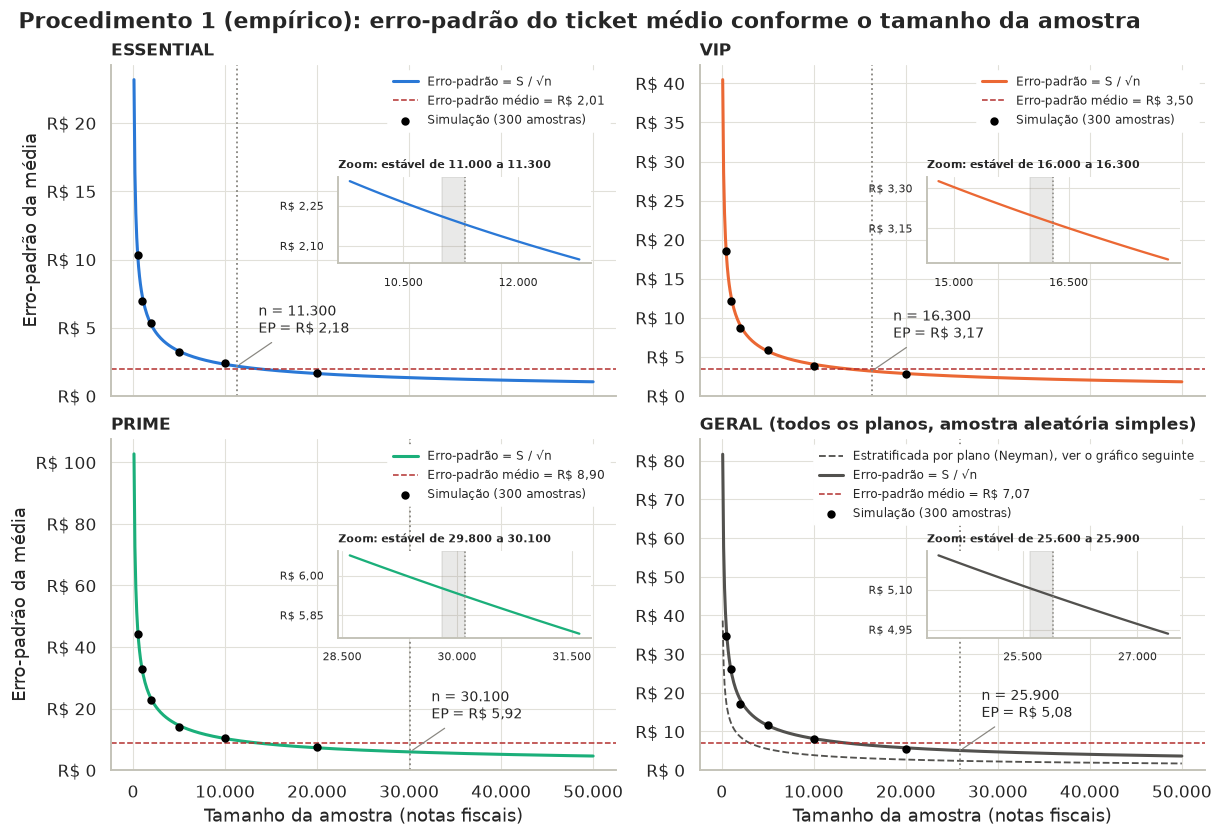

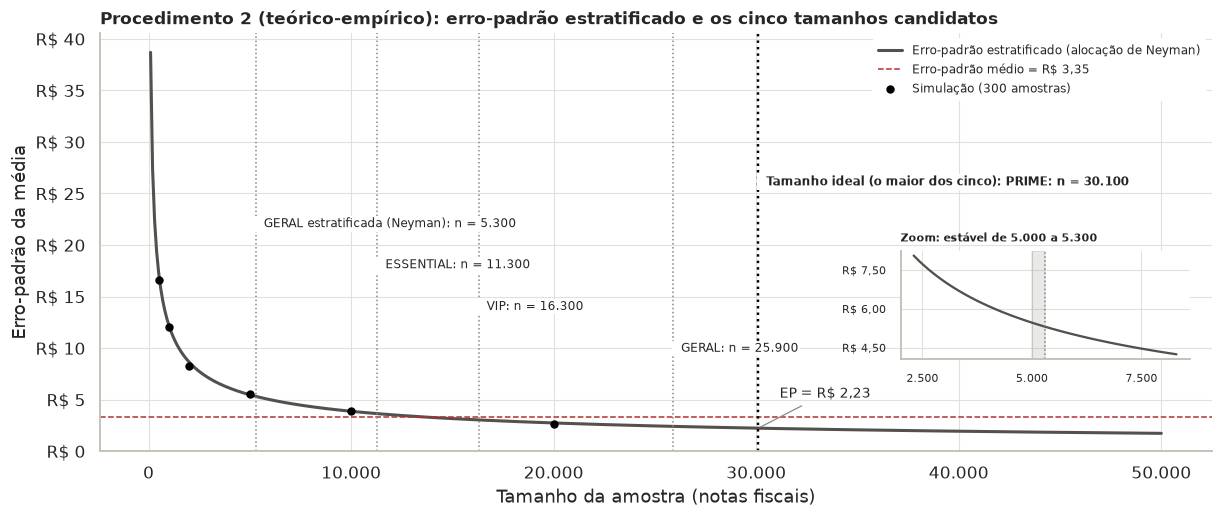

**Ponto de estabilização (empírico: queda de até R\$ 0,01 por passo; estratificado: queda abaixo de 1%; 3 passos seguidos de 100 notas). Tamanho ideal: o maior dos cinco, n = 30.100**

Categoria,Notas na base,Média (R$),Desvio-padrão (R$),Erro-padrão médio da curva (R$),n pela regra,Erro-padrão (R$),Margem de 95% (R$),Margem / média (%)
ESSENTIAL,716.654,"380,69","231,84","2,01",11.300,"2,18","4,27","1,12"
VIP,236.526,"884,05","404,75","3,50",16.300,"3,17","6,21","0,70"
PRIME,166.820,"2.283,61","1.027,56","8,90",30.100,"5,92","11,61","0,51"
GERAL,1.120.000,"770,42","816,84","7,07",25.900,"5,08","9,95","1,29"
GERAL estratificada (Neyman),1.120.000,"770,42",n/a,"3,35",5.300,"5,31","10,42","1,35"


&nbsp;

**Sensibilidade aos parâmetros de estabilização (grade até 200.000 notas)**

Configuração,ESSENTIAL,VIP,PRIME,GERAL,GERAL estratificada (Neyman),Tamanho ideal (o maior),Erro-padrão estratificado (R$),Margem de 95% (% da média)
"Adotada: R$ 0,01 e 3 pontos; estratificado 1% e 3 pontos",11.300,16.300,30.100,25.900,5.300,30.100,"2,23","0,57"
"Exemplo do material: R$ 0,001 e 10 pontos; estratificado 0,1% e 3 pontos",52.200,75.300,139.200,119.600,50.300,139.200,"1,04","0,26"


...

,Peso na base (Wh),Desvio-padrão (Sh),Wh x Sh,Notas na amostra (nh),Parte da amostra (%)
Plano,,,,,
ESSENTIAL,"0,640","231,842","148,349",11.542,"38,346"
VIP,"0,211","404,753","85,477",6.650,"22,093"
PRIME,"0,149","1.027,559","153,051",11.908,"39,561"


&nbsp;

**Notas necessárias para cada margem de erro, a 95% de confiança**

Categoria,±5% da média,±2% da média,±1% da média
ESSENTIAL,570,3.562,14.248
VIP,323,2.014,8.053
PRIME,312,1.945,7.778
GERAL,1.728,10.796,43.183
GERAL estratificada (Neyman),388,2.422,9.687


&nbsp;

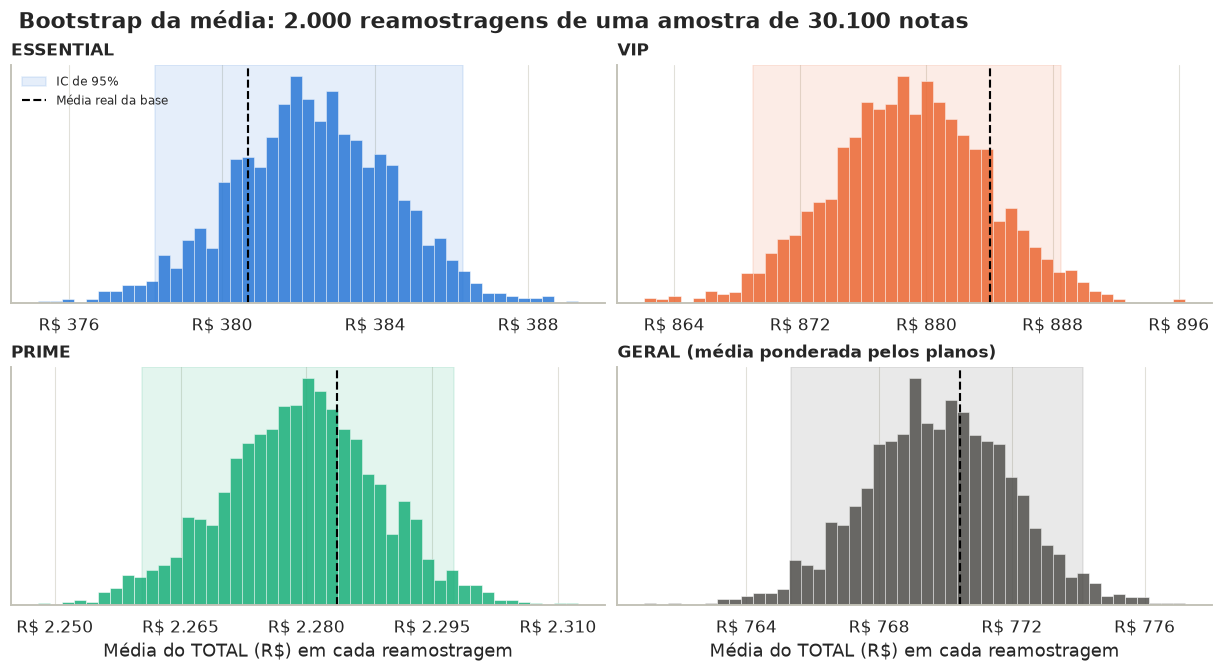

**Bootstrap: erro-padrão e intervalo de confiança**

Categoria,Notas na amostra,Média estimada (R$),Erro-padrão bootstrap (R$),IC de 95%,Média real da base (R$),O IC contém a média real?
ESSENTIAL,11.542,"382,41","2,07","R$ 378,25 a R$ 386,30","380,69",sim
VIP,6.650,"879,01","4,94","R$ 869,02 a R$ 888,52","884,05",sim
PRIME,11.908,"2.279,08","9,33","R$ 2.260,36 a R$ 2.297,58","2.283,61",sim
GERAL,30.100,"769,79","2,23","R$ 765,36 a R$ 774,13","770,42",sim


&nbsp;

**Resumo da A1.1**

,Valor
Tamanho ideal: o maior dos cinco tamanhos (n),30.100
Os cinco tamanhos,"ESSENTIAL: 11.300, VIP: 16.300, PRIME: 30.100, GERAL: 25.900, GERAL estratificada (Neyman): 5.300"
Alocação de Neyman ESSENTIAL / VIP / PRIME,11.542 / 6.650 / 11.908
Erro-padrão estratificado com n notas,"R$ 2,23"
Margem de 95% do ticket médio,"±R$ 4,37 (0,57% da média)"
Erro-padrão de uma amostra simples do mesmo tamanho,"R$ 4,71"
Amostra simples com a mesma precisão (n),134.182
IC normal de 95% que contêm a média real (500 amostras simuladas),"93,8%"


&nbsp;

In [24]:
# Cálculo e gráficos da A1.1
resultado_a1_1 = AtividadeA1_1(base)

**Conclusão**

Adotamos uma amostra de **30.100 notas fiscais**, o maior dos cinco tamanhos calculados: 11.300 no ESSENTIAL, 16.300 no VIP, 30.100 no PRIME, 25.900 no geral e 5.300 pelo procedimento estratificado. O PRIME determina o tamanho final porque tem a maior dispersão do gasto, com desvio-padrão de R\$ 1.027,56.

Pela alocação de Neyman, sorteamos 11.542 notas do ESSENTIAL, 6.650 do VIP e 11.908 do PRIME. Essa divisão resulta em erro-padrão de R\$ 2,23 e margem de ±R\$ 4,37 para o ticket médio, a 95% de confiança. A margem corresponde a 0,57% da média da base. No cenário de 5.000 notas por dia, o tamanho equivale a cerca de seis dias de vendas.

A estratificação melhora a precisão: uma amostra simples de 30.100 notas teria erro-padrão de R\$ 4,71. Para alcançar a mesma precisão da estratificada, seriam necessárias cerca de 134.182 notas em uma amostra simples.

**Escolha dos parâmetros**

Usamos queda de até R\$ 0,01 por passo em três passos seguidos no procedimento empírico, e queda relativa abaixo de 1% no estratificado. A queda relativa deste último depende do tamanho da amostra, e não dos desvios-padrão: com passo de 100, ele estabiliza em 5.300 notas. Seu resultado entra na comparação dos cinco tamanhos; a alocação de Neyman é aplicada ao tamanho final.

Com os parâmetros do exemplo do material (R\$ 0,001 e dez pontos no empírico; 0,1% no estratificado), o tamanho final subiria para 139.200 notas, com margem de ±0,26%. Mantivemos a configuração adotada pelo custo de coletar 4,6 vezes mais notas para reduzir a margem em cerca de 0,3 ponto percentual. Portanto, 30.100 é o tamanho escolhido para esses parâmetros.

**Conferência dos resultados**

Os quatro intervalos bootstrap contêm as médias da base. Na simulação de 500 amostras, o intervalo normal de 95% conteve a média em 93,8% dos casos. A linha vermelha nos gráficos marca o erro-padrão médio da curva até 50.000 notas; a estabilização é indicada na janela de zoom.

In [25]:
help(AtividadeA1_1)

Help on function AtividadeA1_1 in module __main__:

AtividadeA1_1(base, n_max=50000, step=100, limiar=0.01, pontos=3, B=2000, limiar_empirico=0.01)
    Calcula o tamanho ideal da amostra para estimar o ticket médio.

    Compara quatro tamanhos do procedimento empírico (por plano e geral)
    com o tamanho estratificado. Adota o maior e o divide por Neyman.

    n_max e step definem a grade; limiar_empirico é a queda absoluta em reais,
    limiar é a queda relativa, e pontos é o número de passos estáveis.
    B define quantas reamostragens usar no bootstrap.

    Mostra cinco curvas, tabelas de precisão e sensibilidade, bootstrap
    e uma simulação de cobertura. Retorna os tamanhos, alocação, amostra,
    réplicas e tabelas em um dicionário.



### Atividade A1.2: Analisar os outliers

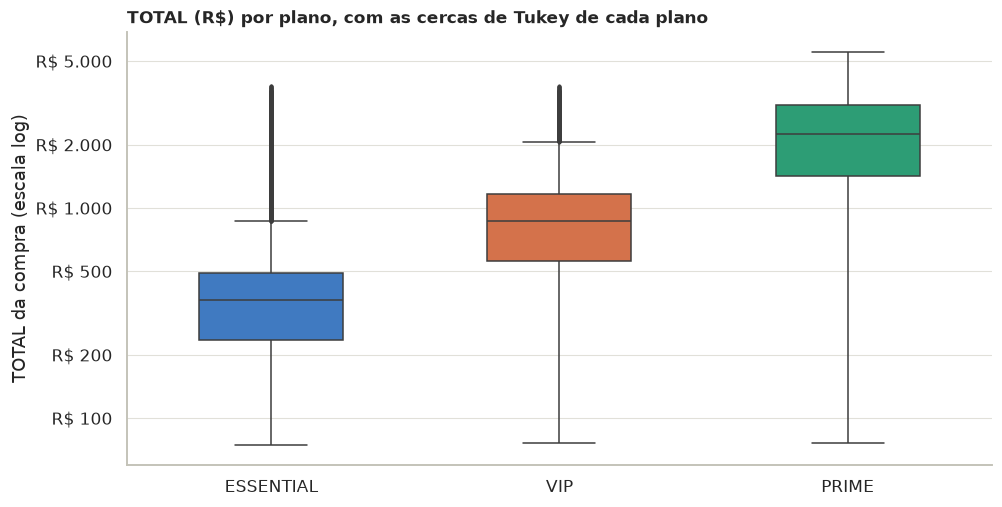

**Outliers por plano**

Plano,Cerca inferior (R$),Cerca superior (R$),Outliers,Outliers (% do plano),Outliers com renda de outro plano (%),Demais notas com renda de outro plano (%),Marcados por uma cerca única (% do plano)
ESSENTIAL,"−144,94","867,97",9.964,"1,39","100,00","0,74","0,61"
VIP,"−346,56","2.069,09",3.005,"1,27","99,50","2,78","1,84"
PRIME,"−1.094,34","5.614,31",0,"0,00",n/a,"5,13","65,19"


&nbsp;

**Quanto os outliers pesam nas medidas do plano**

Plano,Média com outliers (R$),Média sem outliers (R$),Mediana (R$),Desvio-padrão com outliers (R$),Desvio-padrão sem outliers (R$)
ESSENTIAL,"380,69","361,12","362,86","231,84","142,43"
VIP,"884,05","861,35","864,00","404,75","350,81"
PRIME,"2.283,61","2.283,61","2.237,05","1.027,56","1.027,56"


&nbsp;

**Totais na base**

,Notas,% da base
Fora das cercas do próprio plano,12.969,"1,16"
"Fora de uma cerca única (92,6% delas no PRIME)",117.483,"10,49"
Renda de outro plano (cortes em R$ 3.587 e R$ 11.732),33.199,"2,96"


&nbsp;

In [26]:
resultado_a1_2 = AtividadeA1_2(base)

**Conclusão**

As cercas calculadas por plano identificaram 12.969 compras como outliers (1,16% da base): 9.964 no ESSENTIAL e 3.005 no VIP. Nenhuma compra do PRIME ficou fora das cercas.

Quase todos esses registros têm renda típica de outro plano, pelos cortes da árvore do Extra 1: 100% dos outliers do ESSENTIAL e 99,5% dos do VIP. Como o gasto acompanha a renda nesta base, optamos por manter essas compras. A classificação como outlier, por si só, não indica erro no registro.

Uma cerca única marcaria 10,5% da base, sendo 92,6% desse grupo do PRIME. Isso mostra por que a comparação dentro de cada plano é mais adequada. No ESSENTIAL, retirar os outliers reduziria o desvio-padrão de R\$ 231,84 para R\$ 142,43, mas também deixaria de representar essas compras.

O tamanho da A1.1 foi mantido. Mesmo com a retirada dos outliers, o PRIME continuaria determinando o maior tamanho, pois não houve outliers nesse plano.

### Atividade A1.3: Testes de Hipóteses ([Link](https://colab.research.google.com/drive/1_YGamH-qOWSNaCKG5kVlLiZPuXv5lT34?usp=sharing))

SAMPLE 1 e SAMPLE 2 têm 30.100 notas cada, com a mesma alocação de Neyman: 11.542 do ESSENTIAL, 6.650 do VIP e 11.908 do PRIME. O segundo sorteio exclui as notas do primeiro.

Aplicamos os testes do Tópico II e uma análise por plano. Na A1.3.2 e na A1.3.3, essa análise usa 2.000 permutações dentro de cada plano. Os testes que exigem pares seguem o pareamento por posição do material, após embaralhar as amostras; não há pares naturais entre as notas.

A ANOVA compara médias e aparece na A1.3.3 e na A1.3.4. Para o BEST FIT, consideramos as premissas dos testes: o TOTAL não é normal, as amostras não têm pares naturais e sua composição por plano é igual.

Um p-valor acima de 0,05 indica que o teste não rejeitou a hipótese nula; ele não comprova igualdade ou independência. Essa interpretação segue a [orientação da American Statistical Association](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf).

In [27]:
sample1, sample2 = AtividadeA1_3(base, resultado_a1_1['n_ideal'])

**SAMPLE 1 e SAMPLE 2 por plano (notas em comum: 0)**

,Notas em cada amostra,Média SAMPLE 1 (R$),Média SAMPLE 2 (R$),Média da base (R$)
Plano,,,,
ESSENTIAL,11.542,"375,55","383,45","380,69"
VIP,6.650,"888,01","888,66","884,05"
PRIME,11.908,"2.278,17","2.278,22","2.283,61"


&nbsp;

#### A1.3.1: Teste de Normalidade

Nesta ETAPA, você deve fazer o **TESTE DE HIPÓTESE DE NORMALIDADE: Anderson-Darling' Test (AD test)** sobre:

*   SAMPLE 1:
*   SAMPLE 2:

**Anderson-Darling por plano e por amostra (na normal, assimetria 0 e curtose 0)**

Amostra,Grupo,n,A²,Crítico 5%,Crítico 1%,Rejeita a normalidade a 5%?,Assimetria,Curtose
SAMPLE 1,ESSENTIAL,11.542,"407,025","0,752","1,035",sim,"5,392","53,891"
SAMPLE 1,VIP,6.650,"54,504","0,752","1,035",sim,"1,313","5,098"
SAMPLE 1,PRIME,11.908,"72,294","0,752","1,035",sim,"0,173","−0,871"
SAMPLE 1,Amostra inteira,30.100,"1.705,078","0,752","1,035",sim,"1,127","0,204"
SAMPLE 2,ESSENTIAL,11.542,"507,951","0,752","1,035",sim,"5,515","50,635"
SAMPLE 2,VIP,6.650,"56,736","0,752","1,035",sim,"1,390","5,557"
SAMPLE 2,PRIME,11.908,"79,822","0,752","1,035",sim,"0,146","−0,925"
SAMPLE 2,Amostra inteira,30.100,"1.746,211","0,752","1,035",sim,"1,126","0,174"


&nbsp;

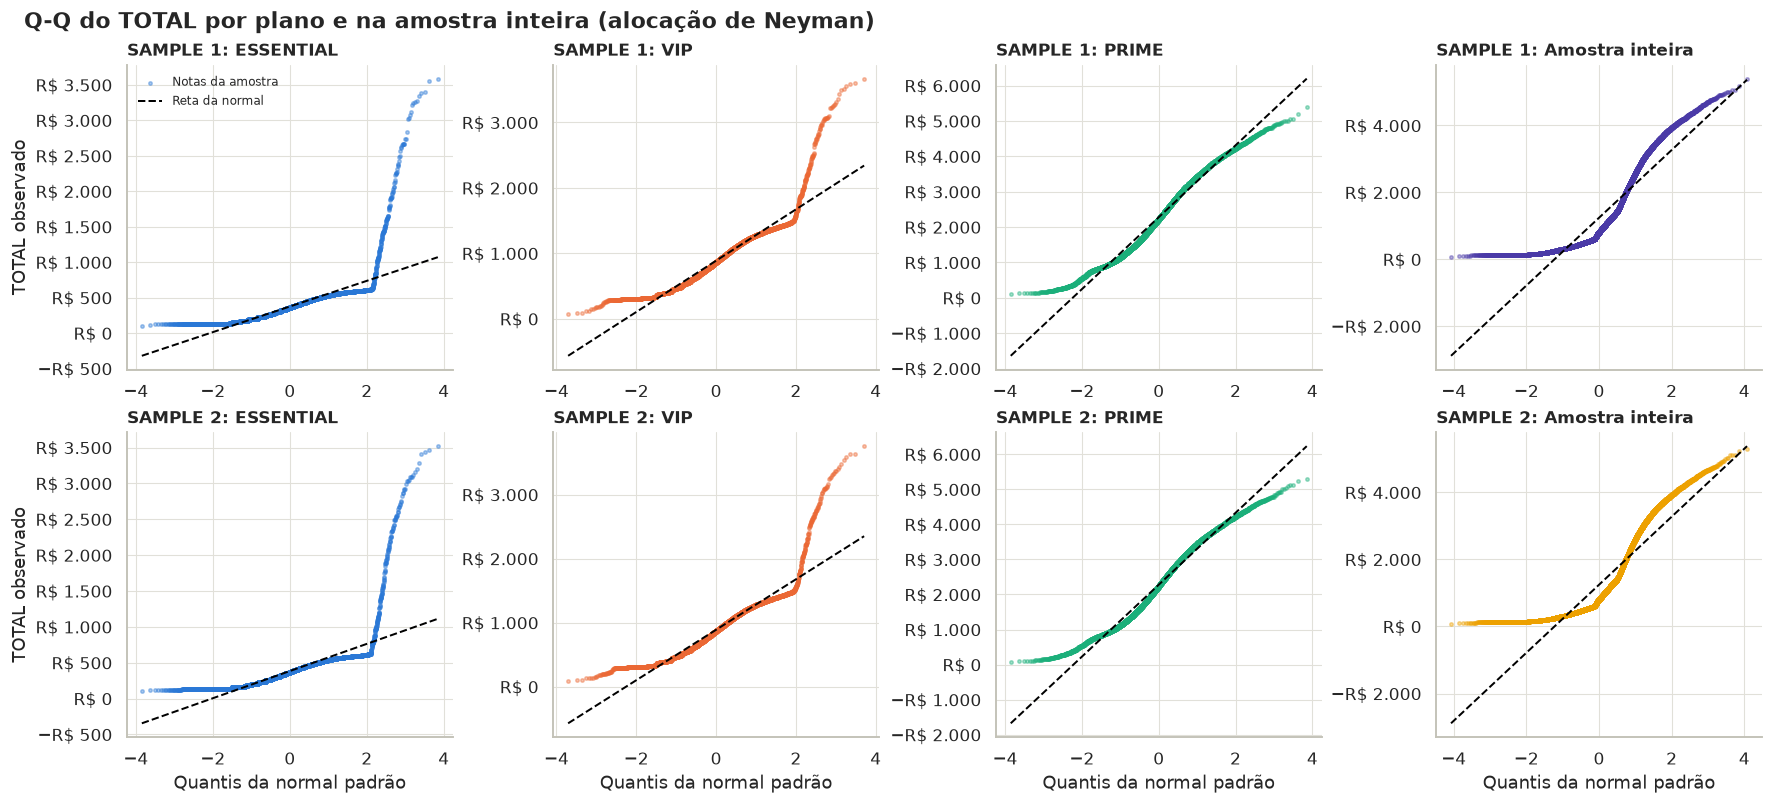

In [28]:
resultado_a1_3_1 = AtividadeA1_3_1(sample1, sample2)

**Conclusão**

O Anderson-Darling rejeitou a normalidade nos oito casos. Dentro dos planos, o A² variou de 54,5 no VIP a 508,0 no ESSENTIAL, acima do valor crítico de 1% (cerca de 1,03). Nas amostras inteiras, passou de 1.700.

O PRIME é quase simétrico, mas apresenta uma distribuição achatada: assimetria entre 0,15 e 0,17 e excesso de curtose de −0,9. No ESSENTIAL, a assimetria fica entre 5,4 e 5,5 e a curtose entre 51 e 54. Sua cauda direita no Q-Q corresponde às compras com renda típica de outro plano, identificadas na A1.2. O VIP apresenta um afastamento intermediário.

Nas amostras inteiras, a mistura dos três planos acentua o afastamento da normal. Além disso, o PRIME representa 39,6% da amostra, contra 14,9% da base.

Para as próximas atividades, usamos testes por postos e permutações, além de comparações de médias com aproximação normal. O bootstrap permite conferir a forma da distribuição das médias; a normalidade do TOTAL não deve ser confundida com a normalidade da média amostral.

#### A1.3.2: Teste de Independência

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Testes de Independência: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

**Testes de independência**

Teste,Estatística,p-valor,Rejeita H0 a 5%?,Rejeições em 1.000 pareamentos
Pearson,"−0,0009","0,875",não,"3,9%"
Spearman,"0,0002","0,975",não,"4,6%"
Kendall,"0,0001","0,975",não,"4,7%"
Qui-quadrado (quartis 4 x 4),"8,4938","0,485",não,"4,1%"
Qui-quadrado por plano (origem x faixa de gasto),"30,6505","0,301",não,n/a


&nbsp;

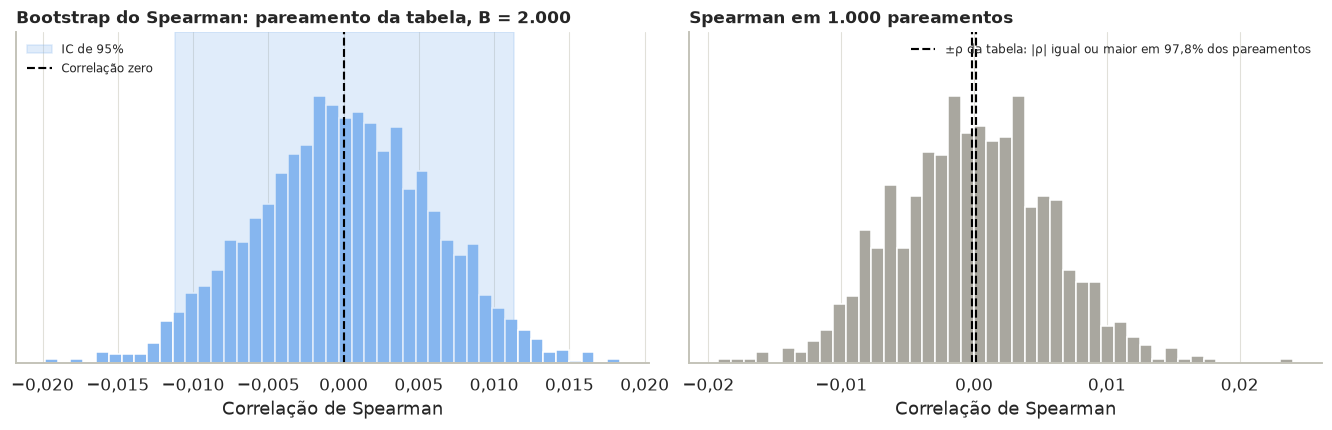

In [29]:
resultado_a1_3_2 = AtividadeA1_3_2(sample1, sample2)

**RESPONDER: SAMPLE 1 e SAMPLE 2 são INDEPENDENTES ???**

**Conclusão**

Não encontramos associação no pareamento utilizado. Os p-valores das três correlações ficaram entre 0,875 e 0,975, o qui-quadrado dos quartis deu 0,485 e a análise por plano, 0,301.

Entre os testes do material, escolhemos o **Spearman** como BEST FIT (p = 0,975), por trabalhar com postos e ser menos sensível aos gastos extremos. O Kendall levou à mesma decisão. Ainda assim, os pares foram formados pela posição das notas: esses resultados descrevem esse pareamento e não demonstram independência entre os sorteios.

Ao repetir o pareamento 1.000 vezes, a proporção de rejeições ficou entre 3,9% e 4,7%. Em 97,8% dos pareamentos, o |ρ| foi igual ou maior que o da tabela, mostrando que a correlação encontrada depende dos pares escolhidos.

As amostras não têm notas em comum, mas o segundo sorteio usa a base que sobrou do primeiro. Essa exclusão chega a 7,1% das notas do PRIME; portanto, ausência de sobreposição não equivale a independência exata.

#### A1.3.3: Teste de Distribuição

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste de Mesma Distribuição: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

**Testes de mesma distribuição**

Teste,Estatística,p-valor,Rejeita H0 a 5%?
Mann-Whitney,"451.578.051,0","0,503",não
Wilcoxon (pareado),"226.368.375,0","0,933",não
Kruskal-Wallis,"0,4480","0,503",não
Kolmogorov-Smirnov,"0,0091","0,164",não
t de Student (compara médias),"−0,3546","0,723",não
ANOVA de um fator (compara médias),"0,1257","0,723",não
"KS por plano, ponderado","0,0174","0,030",sim


&nbsp;

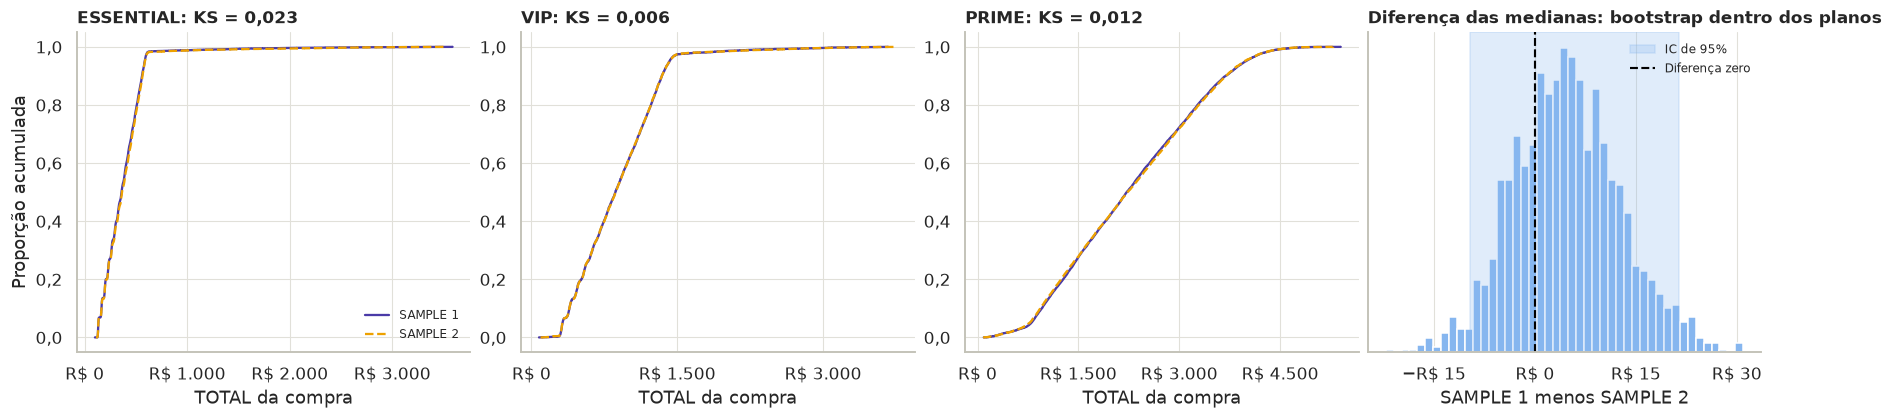

In [30]:
resultado_a1_3_3 = AtividadeA1_3_3(sample1, sample2, pesos_dos_planos(base))

**RESPONDER: SAMPLE 1 e SAMPLE 2 tem a MESMA DISTRIBUIÇÃO DOS DADOS ???**

**Conclusão**

Nas amostras inteiras, o Mann-Whitney não rejeitou a hipótese nula (p = 0,503). Ele foi escolhido como **BEST FIT** entre os testes do material porque trabalha com postos e não exige pares. O Kruskal-Wallis apresentou o mesmo p-valor, e o KS geral deu 0,164. O Mann-Whitney sozinho não verifica todas as possíveis diferenças de forma entre distribuições; por isso também examinamos as curvas acumuladas e o KS.

A análise por plano apresentou um resultado diferente: o KS ponderado deu p = 0,030, abaixo de 5%. A distância ponderada foi de 1,7 ponto percentual na curva acumulada; por plano, as distâncias foram 0,023 no ESSENTIAL, 0,006 no VIP e 0,012 no PRIME. Há, portanto, uma diferença detectada por essa análise, embora as curvas fiquem próximas e o intervalo da diferença das medianas inclua zero.

Os resultados gerais são compatíveis com distribuições próximas, mas a verificação por plano impede afirmar que todos os testes concordam com igualdade. O Wilcoxon usa pares artificiais neste exercício; o t de Student e a ANOVA, por sua vez, comparam médias.

#### A1.3.4: Teste das Médias Amostrais

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste das Médias Amostrais: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

**Testes de médias**

Teste,Estatística,p-valor,Rejeita H0 a 5%?
t de Student (independentes),"−0,3546","0,723",não
t pareado,"−0,3552","0,722",não
ANOVA de um fator,"0,1257","0,723",não
Contraste estratificado (médias ponderadas),"−1,6347","0,102",não


&nbsp;

**Médias simples e ponderadas, com IC de 95% da diferença**

,SAMPLE 1 (R$),SAMPLE 2 (R$),Diferença (R$),IC de 95% da diferença
Média simples (t de Student),"1.241,47","1.244,66","−3,19","−R$ 20,82 a R$ 14,44"
Média ponderada pelos planos (bootstrap),"767,16","772,36","−5,19","−R$ 11,19 a R$ 1,02"


&nbsp;

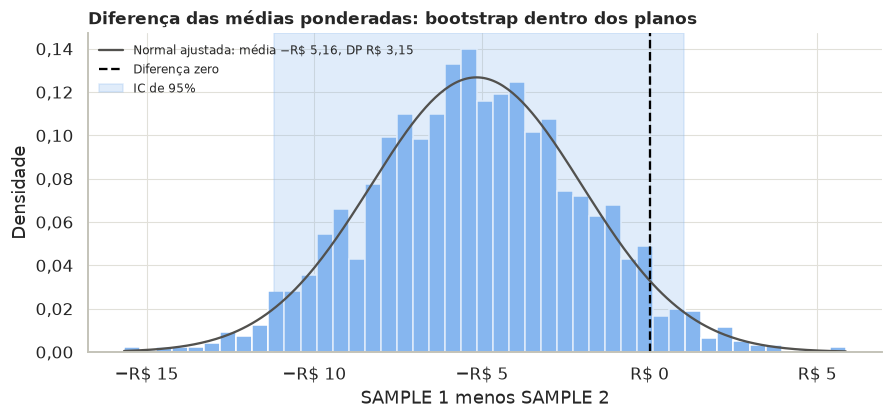

In [31]:
resultado_a1_3_4 = AtividadeA1_3_4(sample1, sample2, pesos_dos_planos(base))

**RESPONDER: SAMPLE 1 e SAMPLE 2 tem as MESMAS MÉDIAS AMOSTRAIS ???**

**Conclusão**

O t de Student para amostras independentes foi o **BEST FIT** do material (p = 0,723). A ANOVA de dois grupos deu a mesma decisão, como esperado pela relação F = t². Nenhum dos testes apresentados rejeitou a igualdade das médias a 5%; isso não demonstra que as médias sejam exatamente iguais.

As médias simples foram R\$ 1.241,47 e R\$ 1.244,66. Elas ficam acima do ticket médio da base porque a alocação de Neyman aumenta a participação do PRIME. Como essa composição é igual nas duas amostras, as médias simples podem ser comparadas entre si.

Para estimar o ticket médio da base, usamos as médias ponderadas: R\$ 767,16 e R\$ 772,36. Sua diferença foi de −R\$ 5,19, com IC de 95% de −R\$ 11,19 a R\$ 1,02 e p = 0,102 no contraste estratificado. O intervalo inclui zero, e o bootstrap da diferença apresentou forma próxima da normal.

## Atividade A2 ([Link](https://colab.research.google.com/drive/1w-72bl_qBnGIR8y9zcGYNcpar9b2JdwA?usp=sharing)): Estatística descritiva

### Atividade A2.1: Analisar as variáveis Quantitativas

**Medidas resumo na SAMPLE 1 (30.100 notas fiscais)**

,Média,Desvio-padrão,CV (%),Mínimo,Q1,Mediana,Q3,Máximo,Assimetria,Curtose
DEPENDENTES,"1,06","0,96","91,06","0,00","0,00","1,00","1,00","4,00","1,19","1,35"
RENDA BRUTO (R$),"11.282,67","8.355,91","74,06","1.819,36","3.283,07","7.768,51","20.502,68","30.984,44","0,47","−1,48"
TOTAL (R$),"1.241,47","1.101,85","88,75","77,82","394,91","809,56","1.841,31","5.400,88","1,13","0,20"
NOTA DE SATISFAÇÃO (%),"69,56","2,33","3,34","68,68","68,68","68,68","68,68","89,39","3,21","11,13"


&nbsp;

**Gasto (TOTAL) por plano: SAMPLE 1 x base completa**

&nbsp;

**Renda e gasto por plano na SAMPLE 1 (Spearman entre renda e gasto: 0,850 na amostra, 0,692 na base)**

&nbsp;

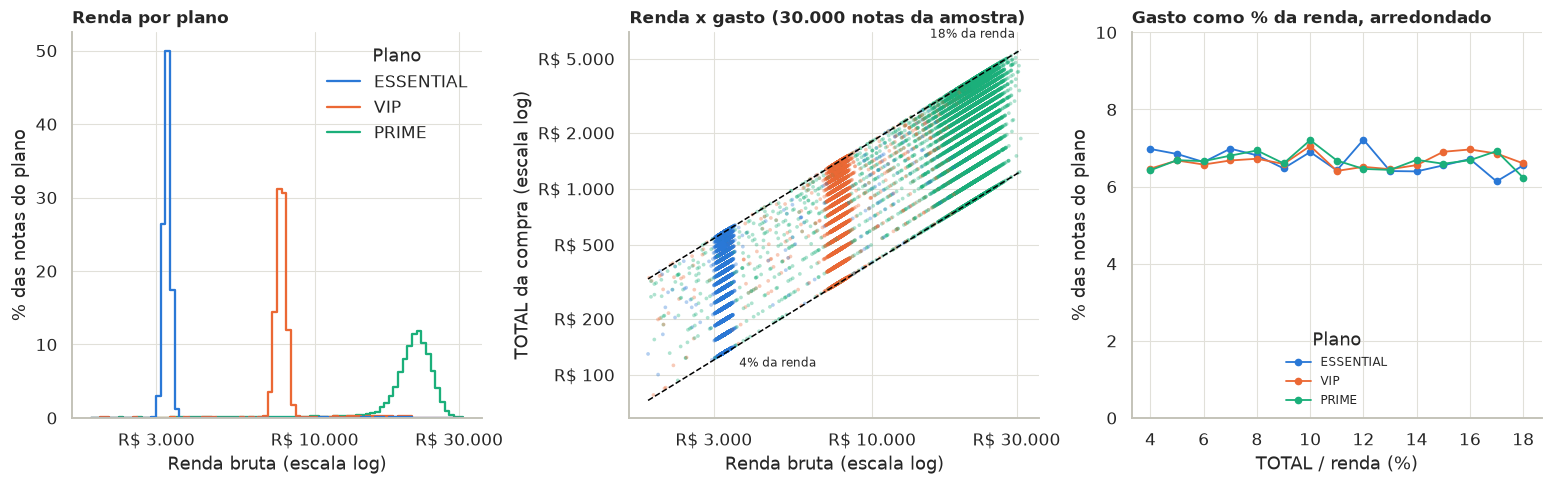

**As 13 medidas químicas dos vinhos na SAMPLE 1**

,Média,Desvio-padrão,Mínimo,Máximo,Valores negativos (%),Maior |correlação| com outra medida,Correlação com o TOTAL,Diferença entre planos (η²)
alcohol,"12,993","0,814","9,731","16,610","0,000","0,011","−0,008","0,000"
malic_acid,"2,328","1,115","−2,157","6,924","1,867","0,009","−0,006","0,000"
ash,"2,367","0,273","0,957","3,388","0,000","0,014","0,000","0,000"
alcalinity_of_ash,"19,485","3,339","5,454","32,977","0,000","0,009","0,006","0,000"
magnesium,"99,633","14,271","42,550","150,593","0,000","0,008","0,002","0,000"
total_phenols,"2,294","0,627","−0,298","4,763","0,010","0,009","0,009","0,000"
flavanoids,"2,032","0,993","−1,887","6,083","2,017","0,013","−0,004","0,000"
nonflavanoid_phenols,"0,362","0,123","−0,145","0,835","0,176","0,008","−0,006","0,000"
proanthocyanins,"1,595","0,570","−0,734","4,067","0,219","0,008","0,005","0,000"
color_intensity,"5,067","2,324","−4,000","14,892","1,458","0,014","0,011","0,000"


&nbsp;

**Nota de satisfação (%) por plano na SAMPLE 1 (média em cada uma das 25 frases de opinião: 69,08 a 69,87)**

,"Iguais a 68,68 (%)","Diferentes de 68,68",Média,Máximo
Plano,,,,
ESSENTIAL,"100,00",0,"68,68","68,68"
VIP,"100,00",0,"68,68","68,68"
PRIME,"51,46",5.780,"70,89","89,39"


&nbsp;

In [32]:
resultado_a2_1 = AtividadeA2_1(sample1, base)

**Conclusão**

As medidas da SAMPLE 1 ficaram próximas das medidas da base dentro de cada plano. A diferença entre as médias do gasto foi menor que R\$ 6 nos três planos, e as medianas e os desvios-padrão também ficaram próximos.

Para o resultado geral, a ponderação é necessária. A média ponderada foi R\$ 767,16, contra R\$ 770,42 na base; a média simples da amostra foi R\$ 1.241,47. Essa diferença vem da maior participação do PRIME na amostra (39,6%, contra 14,9% na base). A composição também afeta a correlação entre renda e gasto: Spearman de 0,850 na amostra e 0,692 na base.

O padrão do gasto é bastante regular: cada compra corresponde a um percentual inteiro da renda, entre 4% e 18%, mais R\$ 1,99. O arredondamento ao centavo explica o restante entre R\$ 1,985 e R\$ 1,995 na tabela. Os 15 percentuais têm frequências próximas nos três planos, e a razão média entre gasto e renda fica em 11%.

As medianas de renda foram R\$ 3.252 no ESSENTIAL, R\$ 7.770 no VIP e R\$ 21.411 no PRIME. O gasto acompanha essa separação e apresenta cauda à direita: na base, a média de R\$ 770,42 supera a mediana de R\$ 472,64.

**Química e nota de satisfação**

Na amostra, nove das 13 medidas químicas têm valores negativos, como acidez málica de −2,2 e prolina de −659. As correlações observadas são muito pequenas (até 0,014), e a diferença entre planos arredonda para η² = 0,000. Mantivemos essas variáveis fora dos modelos por seus problemas de qualidade.

A nota de satisfação vale 68,68 em todo o ESSENTIAL e VIP da amostra e varia apenas no PRIME. Sua média por frase de opinião fica entre 69,08 e 69,87, oferecendo pouca distinção entre as respostas. A A3 usa a classificação das frases.

### Atividade A2.2: Analisar as variáveis Qualitativas

**Frequências na SAMPLE 1 (30.100 notas) e na base completa**

Variável,Categoria,Notas na amostra,% na amostra,% na base
REGIÃO,SUDESTE,20.264,"67,3","67,0"
REGIÃO,SUL,4.701,"15,6","16,0"
REGIÃO,CENTRO-OESTE,2.658,"8,8","9,0"
REGIÃO,NORDESTE,1.856,"6,2","6,0"
REGIÃO,NORTE,621,"2,1","2,0"
SEXO,MASCULINO,26.239,"87,2","87,0"
SEXO,FEMININO,3.861,"12,8","13,0"
ESTADO CIVIL,CASADO,16.711,"55,5","55,0"
ESTADO CIVIL,SOLTEIRO,11.032,"36,7","36,9"
ESTADO CIVIL,DESQUITADO(A) / VIÚVO(A),2.357,"7,8","8,0"


&nbsp;

**Associação com o plano e com o gasto, na SAMPLE 1**

Característica,V de Cramér com o plano,p-valor (qui-quadrado),η² com o TOTAL
REGIÃO,"0,0086","0,817","0,0000"
SEXO,"0,0010","0,985","0,0000"
ESTADO CIVIL,"0,0125","0,052","0,0002"
DEPENDENTES,"0,0141","0,155","0,0002"
PLANO (para comparar),n/a,n/a,"0,6098"


&nbsp;

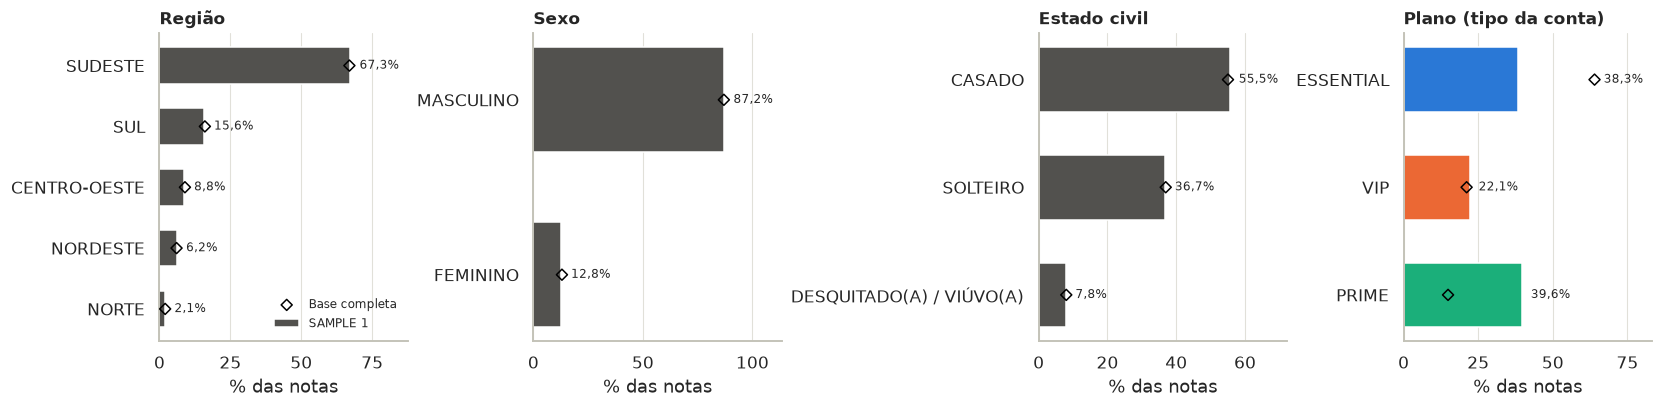

In [33]:
resultado_a2_2 = AtividadeA2_2(sample1, base)

**Conclusão**

A composição da SAMPLE 1 ficou próxima da base para região, sexo, estado civil e dependentes, com diferenças de até meio ponto percentual. Na amostra, 67,3% das notas são do Sudeste, 87,2% são de homens, 55,5% de casados e 52,8% de pessoas com um dependente.

A distribuição dos planos é diferente por escolha do desenho amostral: ESSENTIAL, VIP e PRIME representam 38,3%, 22,1% e 39,6% da amostra, contra 64,0%, 21,1% e 14,9% da base. Por isso, ponderamos as estimativas gerais pelos pesos dos planos na base.

As associações de região, sexo, estado civil e dependentes com o plano foram pequenas: V de Cramér até 0,014, com p-valores entre 0,052 e 0,985. Com o gasto, o η² chegou a 0,0002, enquanto o η² do plano foi 0,61. Nesta base, o plano separa o gasto muito mais que essas características.

As mulheres representam 12,8% das notas da amostra (3.861 respostas). Esse grupo menor terá intervalos mais largos na pesquisa de satisfação.

## Atividade A3: Resultado da Pesquisa de Satisfação

Fazer o resultado da Pesquisa de satisfação do cliente em porcentagem (%):
* Geral
* Por Sexo

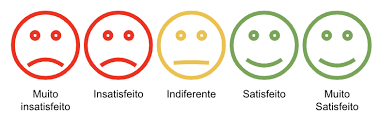

### Atividade A3.1: Discretizar a Variável Qualitativa (OPINIÃO DO CLIENTE)

In [34]:
frases_a3_1 = AtividadeA3_1(base, sample1)

**Níveis de satisfação**

,Frases,% das notas na base,% das notas na SAMPLE 1,% na base se as frases regulares fossem Indiferente
NÍVEL DE SATISFAÇÃO,,,,
Muito insatisfeito,5,"1,00","0,99","1,00"
Insatisfeito,5,"4,00","3,80","0,00"
Indiferente,5,"15,00","14,49","19,00"
Satisfeito,5,"77,00","77,89","77,00"
Muito satisfeito,5,"3,00","2,83","3,00"


&nbsp;

**Classificação das 25 frases**

Nível,Frase,Notas,%
Muito insatisfeito,Senti que faltou qualidade no atendimento da UVVine,2.287,"0,20"
Muito insatisfeito,Tive uma experiência ruim com a UVVine,2.258,"0,20"
Muito insatisfeito,Não gostei do atendimento na UVVine,2.251,"0,20"
Muito insatisfeito,Serviço deixou a desejar na UVVine,2.225,"0,20"
Muito insatisfeito,Produto chegou atrasado na UVVine,2.179,"0,19"
Insatisfeito,"Atendimento comum, poderia melhorar em cordialidade a UVVine",9.056,"0,81"
Insatisfeito,"Nada demais, serviço regular na UVVine",9.033,"0,81"
Insatisfeito,"Experiência regular, não atendeu a política de cashback da UVVine",9.018,"0,81"
Insatisfeito,"Foi aceitável, esperava mais da UVVine",8.857,"0,79"
Insatisfeito,"Razoável, com margem de melhora no preço médio da UVVine",8.836,"0,79"


&nbsp;

**Conclusão**

Distribuímos as 25 frases em cinco níveis de satisfação, com cinco frases por nível. Na base, as proporções foram 1% de muito insatisfeitos, 4% de insatisfeitos, 15% de indiferentes, 77% de satisfeitos e 3% de muito satisfeitos. Na SAMPLE 1, as proporções sem ponderação ficaram próximas: 1,0%, 3,8%, 14,5%, 77,9% e 2,8%.

A classificação mais discutível é a das frases de tom regular, como “esperava mais” e “poderia melhorar”. Nós as colocamos em Insatisfeito. Se fossem classificadas como Indiferente, a proporção de insatisfeitos na base cairia de 5% para 1%. Essa escolha precisa ser considerada ao interpretar a pesquisa.

### Atividade A3.2: Análise Bootstrap do resultado da Pesquisa de Satisfação

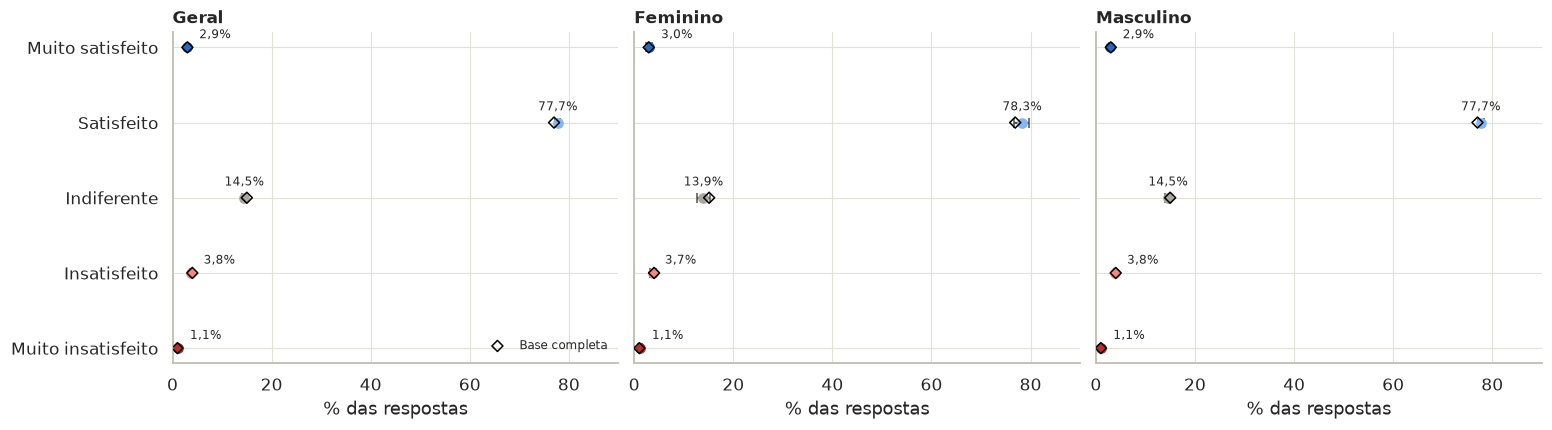

**Pesquisa na SAMPLE 1: 30.100 respostas (3.861 de mulheres e 26.239 de homens), bootstrap com B = 2.000**

Grupo,Nível,Estimativa (%),IC 95% inferior (%),IC 95% superior (%),Base completa (%),O IC contém o valor da base?
GERAL,Muito insatisfeito,"1,1","0,9","1,2","1,0",sim
GERAL,Insatisfeito,"3,8","3,6","4,1","4,0",sim
GERAL,Indiferente,"14,5","14,0","14,9","15,0",não
GERAL,Satisfeito,"77,7","77,2","78,3","77,0",não
GERAL,Muito satisfeito,"2,9","2,7","3,2","3,0",sim
FEMININO,Muito insatisfeito,"1,1","0,7","1,5","1,0",sim
FEMININO,Insatisfeito,"3,7","3,1","4,4","4,0",sim
FEMININO,Indiferente,"13,9","12,7","15,2","15,1",sim
FEMININO,Satisfeito,"78,3","76,7","79,7","76,9",sim
FEMININO,Muito satisfeito,"3,0","2,3","3,6","2,9",sim


&nbsp;

In [35]:
resultado_a3_2 = AtividadeA3_2(base, sample1)

**Conclusão**

As estimativas ponderadas da SAMPLE 1 ficaram próximas das proporções da base. No grupo geral, os intervalos de 95% têm largura de até 1,1 ponto percentual. Considerando os três grupos, 12 dos 15 intervalos contêm o valor da base; nos outros três, o valor fica entre 0,1 e 0,2 ponto fora do intervalo.

Por exemplo, o nível Satisfeito foi estimado em 77,7%, com intervalo de 77,2% a 78,3%, enquanto a base tem 77,0%. Um intervalo de 95% não garante cobertura em todo sorteio, e esses 15 intervalos usam as mesmas respostas; seus resultados não são independentes.

No grupo feminino, com 3.861 respostas, os intervalos ficaram cerca de três vezes mais largos. Para Satisfeito, o intervalo foi de 76,7% a 79,7%; todos os intervalos desse grupo contêm os valores da base.

O tamanho da A1.1 foi escolhido para estimar o ticket médio. Para obter a mesma precisão nas estimativas de satisfação das mulheres, seria necessário aumentar a amostra desse grupo.

### Atividade A3.3: Resultado Final da Pesquisa de Satisfação

**Resultado da pesquisa na SAMPLE 1 (30.100 notas): estimativa e IC de 95%**

,Geral,Feminino,Masculino
Muito satisfeito,"2,9% (2,7% a 3,2%)","3,0% (2,3% a 3,6%)","2,9% (2,7% a 3,2%)"
Satisfeito,"77,7% (77,2% a 78,3%)","78,3% (76,7% a 79,7%)","77,7% (77,1% a 78,3%)"
Indiferente,"14,5% (14,0% a 14,9%)","13,9% (12,7% a 15,2%)","14,5% (14,0% a 15,0%)"
Insatisfeito,"3,8% (3,6% a 4,1%)","3,7% (3,1% a 4,4%)","3,8% (3,6% a 4,1%)"
Muito insatisfeito,"1,1% (0,9% a 1,2%)","1,1% (0,7% a 1,5%)","1,1% (0,9% a 1,2%)"
Satisfeitos (Satisfeito + Muito satisfeito),"80,7% (80,1% a 81,2%)","81,2% (79,8% a 82,6%)","80,6% (80,0% a 81,1%)"
Indiferentes,"14,5% (14,0% a 14,9%)","13,9% (12,7% a 15,2%)","14,5% (14,0% a 15,0%)"
Insatisfeitos (Insatisfeito + Muito insatisfeito),"4,9% (4,6% a 5,2%)","4,8% (4,1% a 5,6%)","4,9% (4,6% a 5,2%)"


&nbsp;

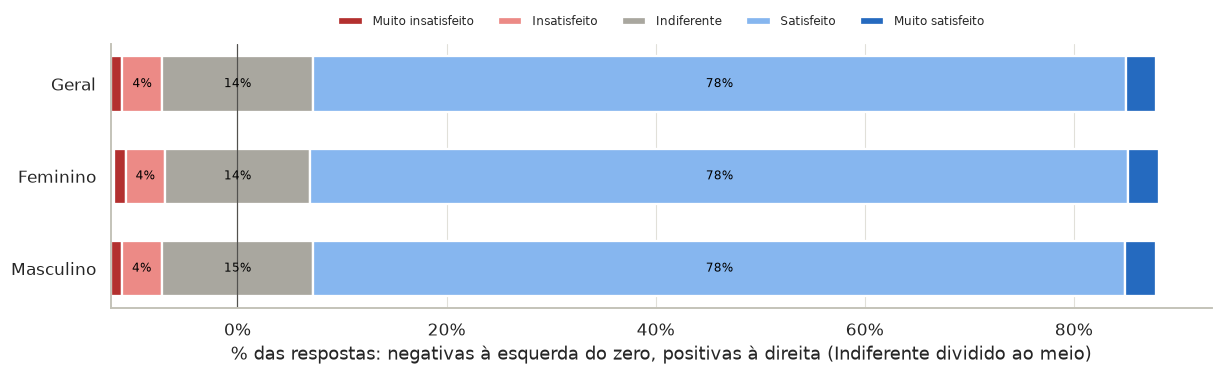

**Diferença entre os sexos na proporção de satisfeitos (SAMPLE 1)**

,Diferença (p.p.),IC de 95% (p.p.)
Feminino − masculino,"0,62","−0,91 a 2,15"


&nbsp;

**Sexo x nível de satisfação (na base completa, só descritivo)**

,Notas,Qui-quadrado,Graus de liberdade,p-valor,V de Cramér
SAMPLE 1,30.100,"2,273",4,"0,686","0,009"
Base completa,1.120.000,"7,505",4,n/a,"0,003"


&nbsp;

In [36]:
resultado_a3_3 = AtividadeA3_3(base, sample1, resultado_a3_2)

**Conclusão**

A estimativa ponderada foi de 80,7% de satisfeitos, 14,5% de indiferentes e 4,9% de insatisfeitos. O intervalo de 95% dos satisfeitos vai de 80,1% a 81,2%. As proporções ficaram próximas dos 80%, 15% e 5% da base.

A diferença entre mulheres e homens na proporção de satisfeitos foi de 0,62 ponto percentual, com IC de −0,91 a 2,15. Não detectamos diferença a partir desse intervalo. A associação entre sexo e satisfação também foi pequena: V de Cramér de 0,009 na SAMPLE 1 (p = 0,686) e 0,003 na base.

No Extra 3, os modelos com cadastro e gasto tiveram desempenho próximo ao acaso para prever insatisfação.

# EXPLORAÇÃO COMPLEMENTAR

Depois das atividades do roteiro, investigamos três questões: a previsão do plano pela renda, a formação de grupos sem usar o plano e a previsão do gasto e da insatisfação.

## Extra 1: dá para prever o plano no momento da adesão?

**Validação cruzada (5 partes, 100.000 notas sorteadas)**

Modelo,Acurácia,Acurácia balanceada,F1 macro,DP do F1 entre partes
Referência: sempre ESSENTIAL,"0,639","0,333","0,260","0,000"
Árvore de decisão (só a renda),"0,971","0,963","0,955","0,004"
Regressão logística (renda e cadastro),"0,971","0,961","0,957","0,004"
Gradient boosting (renda e cadastro),"0,970","0,961","0,956","0,003"


&nbsp;

**Plano atual x classe prevista pela renda (base completa)**

Classe prevista pela árvore,ESSENTIAL,VIP,PRIME
Plano atual,,,
ESSENTIAL,701.478,7.119,8.057
VIP,1.459,227.054,8.013
PRIME,1.474,7.077,158.269


&nbsp;

**Regra da árvore aplicada à base completa**

,Valor
Cortes de renda que mudam a classe,R$ 3.587 e R$ 11.732
Registros com classe acima do plano atual,"23.189 (2,1%)"
Registros com classe abaixo do plano atual,"10.010 (0,9%)"


&nbsp;

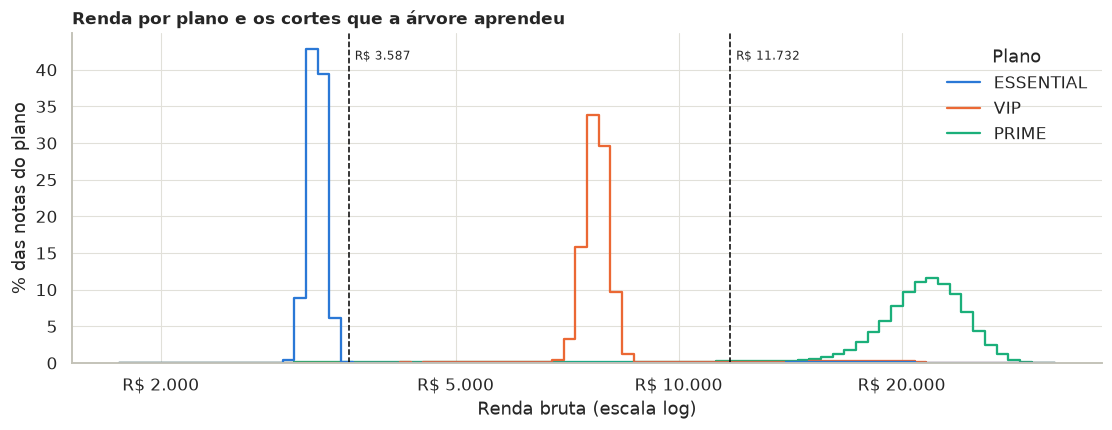

**Árvore fora do treino, por sexo e região**

Variável,Grupo,n,Acurácia balanceada,F1 macro
SEXO,MASCULINO,86.902,"0,963","0,956"
SEXO,FEMININO,13.098,"0,961","0,953"
REGIÃO,SUL,16.286,"0,964","0,957"
REGIÃO,NORDESTE,5.892,"0,961","0,955"
REGIÃO,SUDESTE,67.018,"0,962","0,955"
REGIÃO,CENTRO-OESTE,8.845,"0,964","0,956"
REGIÃO,NORTE,1.959,"0,971","0,961"


&nbsp;

**Árvore fora do treino, por plano**

Plano,Recall fora do treino
ESSENTIAL,"0,980"
VIP,"0,957"
PRIME,"0,951"


&nbsp;

In [37]:
resultado_extra1 = Extra1_PrevisaoDoPlano(base)

**Conclusão**

A renda permitiu prever 97,1% dos planos, com acurácia balanceada de 96,3%. A árvore usou dois cortes, em R\$ 3.587 e R\$ 11.732. Os modelos que acrescentaram região, sexo, estado civil e dependentes não apresentaram melhora relevante, e o desempenho por sexo e região foi semelhante.

Ao aplicar a árvore à base completa, encontramos 23.189 notas (2,1%) com classe prevista acima do plano atual e 10.010 (0,9%) com classe abaixo. Esses registros ajudam a interpretar os outliers da A1.2. A regra descreve os dados simulados; uma decisão de troca de plano exigiria informações comerciais adicionais.

## Extra 2: sem olhar o plano, as notas formam grupos naturais?

**Perfil dos 2 grupos encontrados (60.000 registros sorteados)**

,Registros,Renda mediana (R$),Gasto mediano (R$),% ESSENTIAL,% VIP,% PRIME
GRUPO,,,,,,
Grupo 1,41.290,"3.260,2","368,1","91,3","8,1","0,6"
Grupo 2,18.710,"11.456,7","1.290,6","3,4","50,0","46,6"


&nbsp;

**Silhueta e concordância com os planos por número de grupos**

,Silhueta,Rand ajustado com os planos
k = 2,"0,647","0,684"
k = 3,"0,631","0,921"
k = 4,"0,604","0,550"
k = 5,"0,606","0,515"
k = 6,"0,599","0,501"


&nbsp;

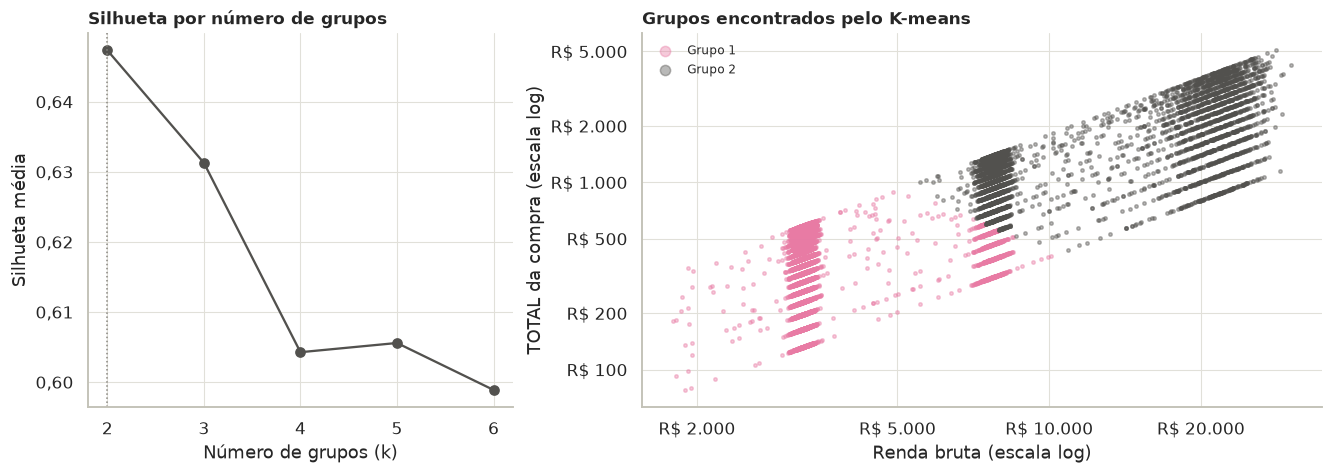

In [38]:
resultado_extra2 = Extra2_Segmentos(base)

**Conclusão**

O K-means separou melhor os dados em dois grupos pelo critério de silhueta (0,647). Um deles é formado principalmente por ESSENTIAL (91%), e o outro reúne VIP e PRIME em proporções próximas. A concordância com os planos, medida pelo Rand ajustado, foi de 0,684.

Com três grupos, a silhueta caiu pouco, para 0,631, e a concordância com os planos subiu para 0,921. Portanto, os três planos aparecem na estrutura de renda e gasto, embora o critério de silhueta favoreça uma divisão mais ampla em dois grupos.

## Extra 3: o que explica o gasto e a satisfação?

**Gasto: mesmo treino (80%) e teste (20%) para todos os modelos**

Modelo,R² no teste (log TOTAL),MAE no teste (log TOTAL)
Referência: média do log,"0,0000","0,6410"
Linear: renda,"0,7049","0,3774"
"Linear: renda, plano e cadastro","0,7047","0,3776"
"Gradient boosting: renda, plano e cadastro","0,7036","0,3783"


&nbsp;

**Regressão do log do gasto com renda, plano e cadastro (treino, erros-padrão HC3)**

,Coeficiente,IC 95% inferior,IC 95% superior,p-valor
Intercepto,"−2,3214","−2,4399","−2,2030","< 0,001"
Plano PRIME (vs. ESSENTIAL),"−0,0158","−0,0432","0,0116","0,259"
Plano VIP (vs. ESSENTIAL),"−0,0103","−0,0250","0,0045","0,172"
Região NORDESTE (vs. CENTRO-OESTE),"−0,0221","−0,0385","−0,0056","0,008"
Região NORTE (vs. CENTRO-OESTE),"−0,0094","−0,0342","0,0154","0,457"
Região SUDESTE (vs. CENTRO-OESTE),"−0,0055","−0,0164","0,0055","0,331"
Região SUL (vs. CENTRO-OESTE),"−0,0089","−0,0217","0,0039","0,175"
Sexo MASCULINO (vs. FEMININO),"−0,0083","−0,0174","0,0008","0,073"
Estado civil DESQUITADO(A) / VIÚVO(A) (vs. CASADO),"−0,0051","−0,0168","0,0066","0,393"
Estado civil SOLTEIRO (vs. CASADO),"0,0007","−0,0058","0,0073","0,826"


&nbsp;

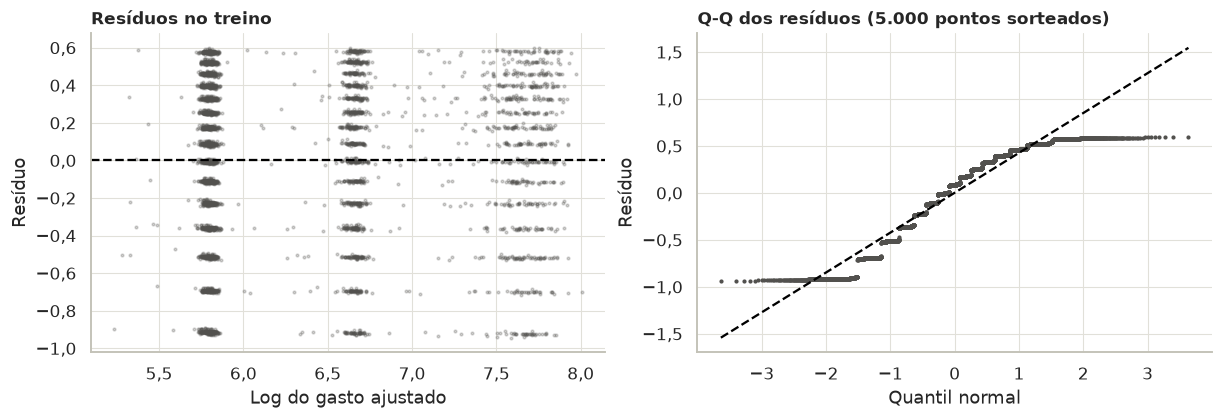

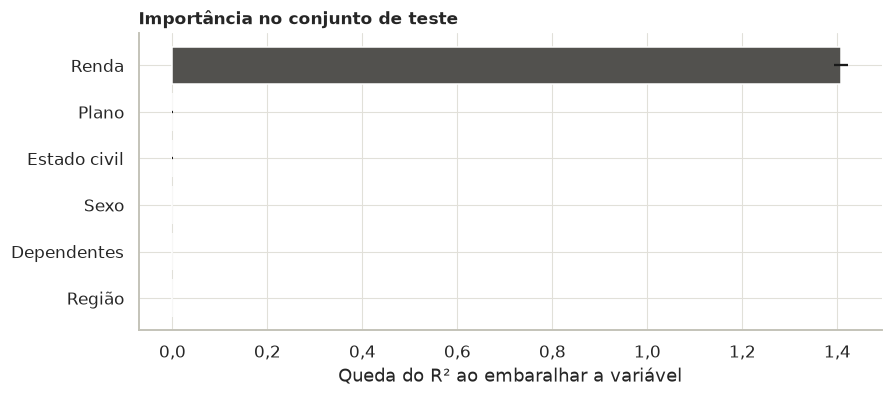

**Prever quem fica insatisfeito: validação cruzada de 5 partes**

,Valor
Insatisfeitos nas 100.000 notas,"5,0%"
AUC,"0,496"
Precisão média,"0,049"
Precisão média de um sorteio (= proporção de insatisfeitos),"0,050"


&nbsp;

In [39]:
resultado_extra3 = Extra3_GastoESatisfacao(base)

**Conclusão**

A renda foi o principal preditor do gasto entre as variáveis avaliadas. O coeficiente do log da renda foi 1,006, com IC de 95% de 0,991 a 1,020, compatível com uma relação proporcional. O modelo só com renda teve R² de 0,705 no teste; acrescentar plano e cadastro não trouxe ganho relevante, e o gradient boosting ficou em 0,704.

O coeficiente do Nordeste apresentou p = 0,008, mas não passou pelo limiar de Bonferroni para os oito coeficientes de cadastro (0,05 / 8 ≈ 0,006). Também não houve ganho de previsão ao acrescentar essas características.

As faixas no gráfico de resíduos correspondem aos diferentes percentuais da renda usados para formar o gasto, observados na A2.1. Os erros-padrão HC3 tratam a variância desigual, mas não resolvem uma possível dependência entre compras do mesmo cliente, que a base não permite identificar.

Para insatisfação, o modelo apresentou AUC de 0,496. Com as variáveis e a validação utilizadas, não obtivemos desempenho superior ao acaso.

# RELATÓRIO FINAL - PARTE 1

O tamanho adotado para a Parte 1 foi de **30.100 notas fiscais**. Esse foi o maior dos cinco tamanhos calculados com os parâmetros escolhidos, determinado pela variabilidade do PRIME. A alocação de Neyman distribuiu a amostra em 11.542 notas do ESSENTIAL, 6.650 do VIP e 11.908 do PRIME.

Para o ticket médio da base, de R\$ 770,42, essa amostra tem margem de ±R\$ 4,37 (0,57%) a 95% de confiança. Uma amostra simples precisaria de cerca de 134.182 notas para a mesma precisão. O ganho vem da separação dos planos, que apresentam níveis de gasto distintos.

As duas amostras usadas nos testes produziram médias ponderadas de R\$ 767,16 e R\$ 772,36. O intervalo da diferença incluiu zero. Na comparação das distribuições, os testes gerais não rejeitaram a hipótese nula, mas o KS por plano detectou uma diferença de 1,7 ponto percentual na curva acumulada (p = 0,030). Assim, a proximidade dos resultados não deve ser tratada como prova de igualdade.

A renda foi a variável mais associada ao plano e ao gasto. As compras seguem um padrão de 4% a 18% da renda, mais R\$ 1,99. Mantivemos os outliers, que correspondem a 1,16% da base, por serem compatíveis com esse padrão. As medidas químicas têm valores negativos, e a nota de satisfação é quase constante; por isso, a pesquisa de satisfação foi feita pelas frases de opinião.

Na base, 80% das respostas foram classificadas como satisfeitas, 15% como indiferentes e 5% como insatisfeitas. A estimativa ponderada de satisfeitos na amostra foi 80,7%, com IC de 95% de 80,1% a 81,2%. Não detectamos diferença entre os sexos, e o modelo de insatisfação teve desempenho próximo ao acaso.

Os resultados dependem das escolhas do exercício. Os parâmetros mais restritos do exemplo do material levariam a 139.200 notas, com margem de ±0,26%. Outra leitura das frases de tom regular reduziria os insatisfeitos de 5% para 1%. Além disso, a base simulada não identifica clientes nem datas, limitando as conclusões sobre compras repetidas e períodos futuros.